# Bellabeat - Estudo de Caso

### A Empresa

Urška Sršen e Sando Mur fundaram a Bellabeat, uma empresa de alta tecnologia que fabrica produtos inteligentes voltados para a saúde.
Sršen usou sua experiência como afiadora para desenvolver uma tecnologia com design bonito que informa e inspira mulheres do mundo todo. 

A coleta de dados sobre atividade, sono, estresse e saúde reprodutiva permitiu que a Bellabeat capacitasse as mulheres com conhecimento sobre sua própria saúde e hábitos. Desde que foi fundada em 2013, a Bellabeat cresceu rapidamente e se posicionou rapidamente como uma empresa de bem-estar voltada para a tecnologia para mulheres.


## 1. Perguntar - Tarefa de Negócio.

Sršen, a cofundadora da bellabeat quer saber como os consumidores usam dispositivos que não são da bellabeat, para descobrir tendências que orientem a estratégia de marketing da empresa. A análise será baseada nos dados públicos do Fitbit.

### Objetivo da análise: 
   * Identificar tendências no uso de dispositivos inteligentes.
   * Como essas tendências podem ser aplicadas nos clientes da bellabeat.
   * Como essas tendências podem ajudar na estratégia de marketing da bellabeat.
      
      

## 2. Preparar - Fonte de Dados

Os dados utilizados nessa análise são de domínio público disponibilizado pelo usuário [Mobius](https://www.kaggle.com/arashnic) na plataforma Kaggle: [Fitbit Fitness Tracker Data](https://www.kaggle.com/datasets/arashnic/fitbit/data).

*Observação: Esse conjunto de dados do Kaggle contém rastreadores pessoais de condicionamento físico de vários usuários do Fitbit. 
Vários usuários elegíveis do Fitbit consentiram com o envio de dados pessoais do rastreador, incluindo resultados ao nível de minuto para atividade física, frequência cardíaca e monitoramento do sono. Inclui informações sobre atividade diária, passos e taxa de calor que podem ser usadas para explorar os hábitos dos usuários*.

#### Origem dos dados:
* Fornecidos via Amazon Mechanical Turk de 12/03/2016 a 12/05/2016.
* 30 usuários participaram voluntariamente.

    
#### Organização:
* Formato largo.
* Separados por tipo de dados.
* chave primaria, id(user), datas e horas.

      
#### Avaliação ROCCC:
* Confiável(Reliable): Sim, os dados foram fornecidos via Amazon Mechanical Turk.
* Original(Original): Sim, foram coletados do dispositivo Fitbit.
* Completo(Comprehensive): Parcial, pequena amostra de 30 usuários em um período limitado.
* Atual(Current): Não, os dados foram coletados 9 anos atrás (2016), assim eles estão desatualizados.
* Citado(Cited): Sim, os dados são fornecidos via Amazon Mechanical Turk, e coletados do dispositivo Fitbit. São dados reais de domínio público.


#### Limitações:
* Número limitado de usuários que participaram voluntariamente, consequentemente amostra pequena (30 usuários).
* Período limitado de coleta de dados, apenas 2 meses.
* Dados Antigos de 2016.

  
*Observação: Como este estudo de caso é para demonstrar os conhecimentos de análises de dados do autor, os dados relativamente antigos vão ser utilizados assim mesmo para a análise. Em uma situação real, os dados antigos seriam sim um problema.*
  

## 3. Processar - Processamento de Dados

A Linguagem R foi utilizada para a analise.

#### Pacotes que foram utilizados na analise.
* tidyverse - conjunto de pacotes como readr, ggplot2, dplyr e lubridate
* corrplot - criar gráficos de correlação
* janitor  - limpar dados
* patchwork - juntar múltiplos gráficos ggplot2 em um único layout


In [1]:
library(tidyverse)
library(corrplot) 
library(janitor) 
library(patchwork)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.1     ✔ tibble    3.2.1
✔ lubridate 1.9.3     ✔ tidyr     1.3.1
✔ purrr     1.0.2     


── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


corrplot 0.92 loaded




Attaching package: ‘janitor’




The following objects are masked from ‘package:stats’:

    chisq.test, fisher.test




#### Arquivos .csv

Os seguintes arquivos foram utilizados para a analise.
*  dailyActivity_merged.csv
*  sleepDay_merged.csv
*  hourlyCalories_merged.csv
*  hourlySteps_merged.csv
*  hourlyIntensities_merged.csv


In [2]:
daily_activity <- read.csv("/kaggle/input/fitbit/mturkfitbit_export_4.12.16-5.12.16/Fitabase Data 4.12.16-5.12.16/dailyActivity_merged.csv")
daily_sleep <- read.csv("/kaggle/input/fitbit/mturkfitbit_export_4.12.16-5.12.16/Fitabase Data 4.12.16-5.12.16/sleepDay_merged.csv")
hourly_calories <- read.csv("/kaggle/input/fitbit/mturkfitbit_export_4.12.16-5.12.16/Fitabase Data 4.12.16-5.12.16/hourlyCalories_merged.csv")
hourly_steps <- read.csv("/kaggle/input/fitbit/mturkfitbit_export_4.12.16-5.12.16/Fitabase Data 4.12.16-5.12.16/hourlySteps_merged.csv")
hourly_intensities <- read.csv("/kaggle/input/fitbit/mturkfitbit_export_4.12.16-5.12.16/Fitabase Data 4.12.16-5.12.16/hourlyIntensities_merged.csv")

#### conjuntos de dados e as suas estruturas

In [3]:
head(daily_activity)
head(daily_sleep)
head(hourly_calories)
head(hourly_steps)
head(hourly_intensities)

,Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories
,<dbl>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>,<int>,<int>
1,1503960366,4/12/2016,13162,8.50,8.50,0,1.88,0.55,6.06,0,25,13,328,728,1985
2,1503960366,4/13/2016,10735,6.97,6.97,0,1.57,0.69,4.71,0,21,19,217,776,1797
3,1503960366,4/14/2016,10460,6.74,6.74,0,2.44,0.40,3.91,0,30,11,181,1218,1776
4,1503960366,4/15/2016,9762,6.28,6.28,0,2.14,1.26,2.83,0,29,34,209,726,1745
5,1503960366,4/16/2016,12669,8.16,8.16,0,2.71,0.41,5.04,0,36,10,221,773,1863
6,1503960366,4/17/2016,9705,6.48,6.48,0,3.19,0.78,2.51,0,38,20,164,539,1728


,Id,SleepDay,TotalSleepRecords,TotalMinutesAsleep,TotalTimeInBed
,<dbl>,<chr>,<int>,<int>,<int>
1,1503960366,4/12/2016 12:00:00 AM,1,327,346
2,1503960366,4/13/2016 12:00:00 AM,2,384,407
3,1503960366,4/15/2016 12:00:00 AM,1,412,442
4,1503960366,4/16/2016 12:00:00 AM,2,340,367
5,1503960366,4/17/2016 12:00:00 AM,1,700,712
6,1503960366,4/19/2016 12:00:00 AM,1,304,320


,Id,ActivityHour,Calories
,<dbl>,<chr>,<int>
1,1503960366,4/12/2016 12:00:00 AM,81
2,1503960366,4/12/2016 1:00:00 AM,61
3,1503960366,4/12/2016 2:00:00 AM,59
4,1503960366,4/12/2016 3:00:00 AM,47
5,1503960366,4/12/2016 4:00:00 AM,48
6,1503960366,4/12/2016 5:00:00 AM,48


,Id,ActivityHour,StepTotal
,<dbl>,<chr>,<int>
1,1503960366,4/12/2016 12:00:00 AM,373
2,1503960366,4/12/2016 1:00:00 AM,160
3,1503960366,4/12/2016 2:00:00 AM,151
4,1503960366,4/12/2016 3:00:00 AM,0
5,1503960366,4/12/2016 4:00:00 AM,0
6,1503960366,4/12/2016 5:00:00 AM,0


,Id,ActivityHour,TotalIntensity,AverageIntensity
,<dbl>,<chr>,<int>,<dbl>
1,1503960366,4/12/2016 12:00:00 AM,20,0.333333
2,1503960366,4/12/2016 1:00:00 AM,8,0.133333
3,1503960366,4/12/2016 2:00:00 AM,7,0.116667
4,1503960366,4/12/2016 3:00:00 AM,0,0.000000
5,1503960366,4/12/2016 4:00:00 AM,0,0.000000
6,1503960366,4/12/2016 5:00:00 AM,0,0.000000


### Formatação

Correção:
* Corrigir as colunas ActivityDate, ActivityDay de char para date.
* Corrigir a coluna ActivityHour de chr para datatime.


Criar:
* Colunas weekday para os conjuntos daily.
* Colunas date, time e weekday para os conjuntos hourly.


In [4]:
#dias da semana 
pt_days <- c("domingo", "segunda", "terça", "quarta", "quinta", "sexta", "sábado")

# Converte a coluna ActivityDate para o formato date
# criando uma nova coluna weekday com os nomes dos dias da semana
daily_activity <- daily_activity %>%
  mutate(ActivityDate = as.Date(ActivityDate, format = "%m/%d/%Y"),
    weekday = factor(pt_days[wday(ActivityDate, week_start = 7)],
                    levels = pt_days, ordered = TRUE))


# Converte a coluna SleepDay para o formato date
# criando uma nova coluna weekday com os nomes dos dias da semana
daily_sleep <- daily_sleep %>%
  mutate(SleepDay = as.Date(SleepDay, format = "%m/%d/%Y"),
         weekday = factor(pt_days[wday(SleepDay, week_start = 7)],
                    levels = pt_days, ordered = TRUE))


#  Convertendo ActivityHour para Formato de Datatime
# Extrair apenas a hora do dia e a data 
# Criando a Coluna weekday com os dias da semana
hourly_calories <- hourly_calories %>%
  mutate(ActivityHour = as.POSIXct(ActivityHour, format = "%m/%d/%Y %I:%M:%S %p", tz = Sys.timezone()),
    time = format(ActivityHour, format = "%Hh"),
    date = as.Date(ActivityHour, format = "%m/%d/%Y"),
          weekday = factor(pt_days[wday(date, week_start = 7)],
                    levels = pt_days, ordered = TRUE))


# Convertendo ActivityHour na tabela hourly_steps para Formato de Datatime
# Extrair apenas a hora do dia e a data 
# Criando a Coluna weekday com os dias da semana
hourly_steps <- hourly_steps %>%
  mutate(ActivityHour = as.POSIXct(ActivityHour, format = "%m/%d/%Y %I:%M:%S %p", tz = Sys.timezone()),
    time = format(ActivityHour, format = "%Hh"),
    date = as.Date(ActivityHour, format = "%m/%d/%Y"),
         weekday = factor(pt_days[wday(date, week_start = 7)],
                    levels = pt_days, ordered = TRUE))


# Convertendo ActivityHour na tabela hourly_intensities para Formato de Datatime
# Extrair apenas a hora do dia e a data 
# Criando a Coluna weekday com os dias da semana
hourly_intensities <- hourly_intensities %>%
  mutate(ActivityHour = as.POSIXct(ActivityHour, format = "%m/%d/%Y %I:%M:%S %p", tz = Sys.timezone()),
    time = format(ActivityHour, format = "%Hh"),
    date = as.Date(ActivityHour, format = "%m/%d/%Y"),
         weekday = factor(pt_days[wday(date, week_start = 7)],
                    levels = pt_days, ordered = TRUE))


####  Limpar e Renomear colunas

Limpar colunas para manter tudo mais consistente e melhor para visualização e renomear as activitydate e sleepday para date para fazer a combinação dos datasets.

In [5]:
clean_names(daily_activity)
daily_activity <- rename_with(daily_activity, tolower)
daily_activity <- rename(daily_activity, "date" = activitydate)

clean_names(daily_sleep)
daily_sleep <- rename_with(daily_sleep, tolower)
daily_sleep <- rename(daily_sleep, "date" = sleepday)

clean_names(hourly_calories)
hourly_calories <- rename_with(hourly_calories, tolower)

clean_names(hourly_steps)
hourly_steps <- rename_with(hourly_steps, tolower)

clean_names(hourly_intensities)
hourly_intensities <- rename_with(hourly_intensities, tolower)

id,activity_date,total_steps,total_distance,tracker_distance,logged_activities_distance,very_active_distance,moderately_active_distance,light_active_distance,sedentary_active_distance,very_active_minutes,fairly_active_minutes,lightly_active_minutes,sedentary_minutes,calories,weekday
<dbl>,<date>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>,<int>,<int>,<ord>
1503960366,2016-04-12,13162,8.50,8.50,0,1.88,0.55,6.06,0,25,13,328,728,1985,terça
1503960366,2016-04-13,10735,6.97,6.97,0,1.57,0.69,4.71,0,21,19,217,776,1797,quarta
1503960366,2016-04-14,10460,6.74,6.74,0,2.44,0.40,3.91,0,30,11,181,1218,1776,quinta
1503960366,2016-04-15,9762,6.28,6.28,0,2.14,1.26,2.83,0,29,34,209,726,1745,sexta
1503960366,2016-04-16,12669,8.16,8.16,0,2.71,0.41,5.04,0,36,10,221,773,1863,sábado
1503960366,2016-04-17,9705,6.48,6.48,0,3.19,0.78,2.51,0,38,20,164,539,1728,domingo
1503960366,2016-04-18,13019,8.59,8.59,0,3.25,0.64,4.71,0,42,16,233,1149,1921,segunda
1503960366,2016-04-19,15506,9.88,9.88,0,3.53,1.32,5.03,0,50,31,264,775,2035,terça
1503960366,2016-04-20,10544,6.68,6.68,0,1.96,0.48,4.24,0,28,12,205,818,1786,quarta


id,sleep_day,total_sleep_records,total_minutes_asleep,total_time_in_bed,weekday
<dbl>,<date>,<int>,<int>,<int>,<ord>
1503960366,2016-04-12,1,327,346,terça
1503960366,2016-04-13,2,384,407,quarta
1503960366,2016-04-15,1,412,442,sexta
1503960366,2016-04-16,2,340,367,sábado
1503960366,2016-04-17,1,700,712,domingo
1503960366,2016-04-19,1,304,320,terça
1503960366,2016-04-20,1,360,377,quarta
1503960366,2016-04-21,1,325,364,quinta
1503960366,2016-04-23,1,361,384,sábado


id,activity_hour,calories,time,date,weekday
<dbl>,<dttm>,<int>,<chr>,<date>,<ord>
1503960366,2016-04-12 00:00:00,81,00h,2016-04-12,terça
1503960366,2016-04-12 01:00:00,61,01h,2016-04-12,terça
1503960366,2016-04-12 02:00:00,59,02h,2016-04-12,terça
1503960366,2016-04-12 03:00:00,47,03h,2016-04-12,terça
1503960366,2016-04-12 04:00:00,48,04h,2016-04-12,terça
1503960366,2016-04-12 05:00:00,48,05h,2016-04-12,terça
1503960366,2016-04-12 06:00:00,48,06h,2016-04-12,terça
1503960366,2016-04-12 07:00:00,47,07h,2016-04-12,terça
1503960366,2016-04-12 08:00:00,68,08h,2016-04-12,terça


id,activity_hour,step_total,time,date,weekday
<dbl>,<dttm>,<int>,<chr>,<date>,<ord>
1503960366,2016-04-12 00:00:00,373,00h,2016-04-12,terça
1503960366,2016-04-12 01:00:00,160,01h,2016-04-12,terça
1503960366,2016-04-12 02:00:00,151,02h,2016-04-12,terça
1503960366,2016-04-12 03:00:00,0,03h,2016-04-12,terça
1503960366,2016-04-12 04:00:00,0,04h,2016-04-12,terça
1503960366,2016-04-12 05:00:00,0,05h,2016-04-12,terça
1503960366,2016-04-12 06:00:00,0,06h,2016-04-12,terça
1503960366,2016-04-12 07:00:00,0,07h,2016-04-12,terça
1503960366,2016-04-12 08:00:00,250,08h,2016-04-12,terça


id,activity_hour,total_intensity,average_intensity,time,date,weekday
<dbl>,<dttm>,<int>,<dbl>,<chr>,<date>,<ord>
1503960366,2016-04-12 00:00:00,20,0.333333,00h,2016-04-12,terça
1503960366,2016-04-12 01:00:00,8,0.133333,01h,2016-04-12,terça
1503960366,2016-04-12 02:00:00,7,0.116667,02h,2016-04-12,terça
1503960366,2016-04-12 03:00:00,0,0.000000,03h,2016-04-12,terça
1503960366,2016-04-12 04:00:00,0,0.000000,04h,2016-04-12,terça
1503960366,2016-04-12 05:00:00,0,0.000000,05h,2016-04-12,terça
1503960366,2016-04-12 06:00:00,0,0.000000,06h,2016-04-12,terça
1503960366,2016-04-12 07:00:00,0,0.000000,07h,2016-04-12,terça
1503960366,2016-04-12 08:00:00,13,0.216667,08h,2016-04-12,terça


#### Verificar dados Invalidos

Verificar dados invalidos em algumas tabelas. 


Nas colunas totalsteps e calories do conjunto daily_activity tem bastante zeros.


Desse modo da para filtrar para evitar problemas durante a analise.
Esses valores podem representar, mau funcionamento, o não uso do dispositivo ou problemas tecnicos.


In [6]:
# Verificação de dados = 0
daily_activity %>%
  summarise(total_linhas = n(),
            zero_passos = sum(totalsteps == 0),
            zeros_calorias = sum(calories == 0))

total_linhas,zero_passos,zeros_calorias
<int>,<int>,<int>
940,77,4


O  dataset daily_activity possui 940 registros, sendo 77 registros com 0 passos(zero_passos) e 4 com 0 calorias(zero_calorias).


Decidi remover esses registros com 0 passos e 0 calorias ja que os dados sao registros por dia, para buscar eliminar possiveis falhas como, dispositivo nao usado naquele dia, problemas tecnicos ou mau funcionamento no dispositivo.


In [7]:
nrow(daily_activity)

# remoção dos registros = 0
daily_activity <- daily_activity %>%
  filter(totalsteps > 0,
         calories > 0)

nrow(daily_activity)


[1] 940

[1] 863

**Com** os registros invalidos: 940


**Sem** os registros invalidos: 863

In [8]:
# remoção dos registros daily_sleep  = 0
daily_sleep %>%
  summarize(total_rows = n(),
            zeros_asleep = sum(totalminutesasleep == 0),
            zeros_timebed = sum(totaltimeinbed == 0))

# remoção dos registros hourly_calories = 0
hourly_calories %>%
  summarize(total_rows = n(),
            zeros_hourlycalories = sum(calories == 0))

total_rows,zeros_asleep,zeros_timebed
<int>,<int>,<int>
413,0,0


total_rows,zeros_hourlycalories
<int>,<int>
22099,0


Os datasets daily_sleep e o hourly_calories não possuem registros = 0

In [9]:
hourly_steps %>%
  summarize(total_rows = n(),
            zeros_hourlysteps = sum(steptotal == 0))

hourly_intensities %>%
  summarize(total_rows = n(),
            zeros_totalintensity = sum(totalintensity == 0))

total_rows,zeros_hourlysteps
<int>,<int>
22099,9297


total_rows,zeros_totalintensity
<int>,<int>
22099,9097




Os conjuntos "hourly_steps" e "hourly_intensities" possuem 22099 registros sendo que cerca de 40% dos registros sao com valores = 0. 

Esses valores = 0 pode significar varias coisa como, a pessoa esta dormindo, em periodos de repulso(assistindo TV, sentando trabalhando) dispotivo parado carregando, dentre outros. E um zero não necessariamente indica um erro ou um dado faltante que precisa ser removido. Em muitos casos, zero significa "inatividade", o que é uma informação valiosa em si. 

Entao esses numeros expressam registros por hora, uma quantia significativa de registros.

#### Verificaçao de dados duplicados ou ausentes

Verificar os a quantidade dos dados duplicados ou ausentes nos data sets. E depois limpar esses dados ja que poderia distorcer a analise.

In [10]:
sum(is.na(daily_activity))
sum(is.na(daily_sleep))
sum(is.na(hourly_calories))
sum(is.na(hourly_steps))
sum(is.na(hourly_intensities))

[1] 0

[1] 0

[1] 0

[1] 0

[1] 0

Os conjuntos daily_activity, daily_sleep, hourly_calories, hourly_steps, hourly_intensities **não** possuem dados ausentes.

In [11]:
sum(duplicated(daily_activity))
sum(duplicated(daily_sleep))
sum(duplicated(hourly_calories))
sum(duplicated(hourly_steps))
sum(duplicated(hourly_intensities))

[1] 0

[1] 3

[1] 0

[1] 0

[1] 0

O conjunto daily_sleep **possui** 3 registros duplicados, os outros conjuntos nao possuem nenhum. Após remove os registros duplicados é possível verificar se não há mais nenhum.

In [12]:
daily_sleep <- daily_sleep %>%
  distinct()

sum(duplicated(daily_activity))
sum(duplicated(daily_sleep))
sum(duplicated(hourly_calories))
sum(duplicated(hourly_steps))
sum(duplicated(hourly_intensities))

[1] 0

[1] 0

[1] 0

[1] 0

[1] 0

## 4. Analisar - Explorar os dados

Explorando tendencias

In [13]:
#Gera um resumo estatistico descritivo das colunas totalsteps,totaldistance e calories
daily_activity %>%
  select(totalsteps,
         totaldistance,
         calories) %>%
  summary()

   totalsteps    totaldistance      calories   
 Min.   :    4   Min.   : 0.00   Min.   :  52  
 1st Qu.: 4923   1st Qu.: 3.37   1st Qu.:1856  
 Median : 8053   Median : 5.59   Median :2220  
 Mean   : 8319   Mean   : 5.98   Mean   :2361  
 3rd Qu.:11092   3rd Qu.: 7.90   3rd Qu.:2832  
 Max.   :36019   Max.   :28.03   Max.   :4900  

Explorando as tendências com o comando summary(), é possível ver média, mediana, mínimos e máximos de cada conjunto.


É possível identificar uma simetria entre a média e a mediana, pois ambos têm valores bem próximos um do outro. Os passos são em média 8000 passos por dias, já a distância em dia de 5.6km por dia isso indica que os usuários são **moderadamente ativos**. Eles não são sedentários, mas também não são grandes atletas.

In [14]:
# Gera um relatorio descritivo das colunas,veryactiveminutes, fairlyactiveminutes,
# lightlyactiveminutes, sedentaryminutes
daily_activity %>%
  select(veryactiveminutes,
         fairlyactiveminutes,
         lightlyactiveminutes,
         sedentaryminutes) %>%
  summary()

 veryactiveminutes fairlyactiveminutes lightlyactiveminutes sedentaryminutes
 Min.   :  0.00    Min.   :  0.00      Min.   :  0.0        Min.   :   0.0  
 1st Qu.:  0.00    1st Qu.:  0.00      1st Qu.:146.5        1st Qu.: 721.5  
 Median :  7.00    Median :  8.00      Median :208.0        Median :1021.0  
 Mean   : 23.02    Mean   : 14.78      Mean   :210.0        Mean   : 955.8  
 3rd Qu.: 35.00    3rd Qu.: 21.00      3rd Qu.:272.0        3rd Qu.:1189.0  
 Max.   :210.00    Max.   :143.00      Max.   :518.0        Max.   :1440.0  

A maioria do tempo dos usuários ainda e gasta com **atividade físicas leve** durante o dia com cerca de 3h28min(208 minutos). É predominante **comportamento sedentário** com cerca de 17h01min(1021 minutos). A proporção de tempo sedentário e muito alta.

#### calculando as médias de atividade física por dias da semana

In [15]:
weekday_activity <- daily_activity %>%
  group_by(weekday) %>%
  summarize("Atividade Leve" = mean(lightlyactiveminutes),
           "Atividade Moderada" = mean(fairlyactiveminutes),
            "Atividade Intensa" = mean(veryactiveminutes),
            "Tempo Sedentário" = mean(sedentaryminutes)) %>%
  pivot_longer(cols = c("Atividade Leve",
                        "Atividade Moderada",
                        "Atividade Intensa",
                        "Tempo Sedentário"),
               names_to = "activity_level",
               values_to = "mean_minutes")

head(weekday_activity)

weekday,activity_level,mean_minutes
<ord>,<chr>,<dbl>
domingo,Atividade Leve,191.37273
domingo,Atividade Moderada,15.98182
domingo,Atividade Intensa,21.98182
domingo,Tempo Sedentário,945.28182
segunda,Atividade Leve,209.51818
segunda,Atividade Moderada,15.27273


#### Calculando as médias diárias das atividades físicas
24h * 60minutos = 1440 minutos

In [16]:
total_dia <- 1440

activity_means <- daily_activity %>%
  summarise("Atividade Intensa" = mean(veryactiveminutes),
            "Atividade Moderada" = mean(fairlyactiveminutes),
            "Atividade Leve" = mean(lightlyactiveminutes),
            "Tempo Sedentário" = mean(sedentaryminutes)) %>%
  pivot_longer(cols = everything(),
               names_to = "activity", values_to = "minutes") %>%
  mutate(percentage = round(minutes / total_dia * 100, 1),
         Label = paste0(percentage, "%"))

head(activity_means)

activity,minutes,percentage,Label
<chr>,<dbl>,<dbl>,<chr>
Atividade Intensa,23.01506,1.6,1.6%
Atividade Moderada,14.77520,1.0,1%
Atividade Leve,210.01622,14.6,14.6%
Tempo Sedentário,955.75319,66.4,66.4%


In [17]:
daily_sleep %>%
  select(totalsleeprecords,
         totalminutesasleep,
         totaltimeinbed) %>%
  summary()

 totalsleeprecords totalminutesasleep totaltimeinbed 
 Min.   :1.00      Min.   : 58.0      Min.   : 61.0  
 1st Qu.:1.00      1st Qu.:361.0      1st Qu.:403.8  
 Median :1.00      Median :432.5      Median :463.0  
 Mean   :1.12      Mean   :419.2      Mean   :458.5  
 3rd Qu.:1.00      3rd Qu.:490.0      3rd Qu.:526.0  
 Max.   :3.00      Max.   :796.0      Max.   :961.0  

A maioria dos usuários está atingindo ou superando as horas de sono recomendadas 7h13 minutos(433 minutos).

A diferença entre o tempo médio na cama, 458.6 minutos e o tempo médio dormindo, 419.5 minutos permanece em torno de **39 minutos**. Isso é o tempo médio que os usuários passam acordados na cama antes de dormir ou após acordar.

#### Combinar e explorar os conjuntos daily_activity e daily_sleep

Combinando daily_activity e daily_sleep através das colunas id, date e weekday, utilizando a função inner_join() para manter somente os registros correspondentes em ambos os conjuntos.

In [18]:
n_distinct(daily_activity$id)
n_distinct(daily_sleep$id)

[1] 33

[1] 24

O conjunto daily_activity possui 33 registros distintos de usuários e o conjunto daily_sleep possui 24.

In [19]:
#combinando informações de sono e atividade diária dos mesmos usuários e dias
combined_daily <- inner_join(daily_sleep, daily_activity, by=c("id", "date", "weekday"))

n_distinct(combined_daily$id)
colnames(combined_daily)


[1] 24

[1] "id"                       "date"                    
 [3] "totalsleeprecords"        "totalminutesasleep"      
 [5] "totaltimeinbed"           "weekday"                 
 [7] "totalsteps"               "totaldistance"           
 [9] "trackerdistance"          "loggedactivitiesdistance"
[11] "veryactivedistance"       "moderatelyactivedistance"
[13] "lightactivedistance"      "sedentaryactivedistance" 
[15] "veryactiveminutes"        "fairlyactiveminutes"     
[17] "lightlyactiveminutes"     "sedentaryminutes"        
[19] "calories"

Após a junção, o número de usuários diminui de 33 para 24.


#### Agrupar e Calcular medias
o conjunto combined_daily por weekday, calcular medias e totalsteps e totalminutesasleep para facilitar a visualização de passos e sono por dia da semana.

In [20]:
#A média diária de passos e a média diária de minutos de sono, 
# separadamente para cada dia da semana
weekdaygrouped_daily <- combined_daily %>%
  group_by(weekday) %>%
  summarize(
    meansteps = mean(totalsteps, na.rm = TRUE),
    meanasleep = mean(totalminutesasleep, na.rm = TRUE))

head(weekdaygrouped_daily)

weekday,meansteps,meanasleep
<ord>,<dbl>,<dbl>
domingo,7297.855,452.7455
segunda,9273.217,419.5000
terça,9182.692,404.5385
quarta,8022.864,434.6818
quinta,8183.516,401.2969
sexta,7901.404,405.4211


### Correlograma

#### funcionamento do correlograma
* Cada célula do gráfico representa a correlação entre duas variáveis.
* O formato de gráfico de pizza usa setores circulares para indicar o valor da correlação.
* Quanto mais preenchido o círculo, mais forte a correlação.
* A direção do preenchimento mostra o sinal da correlação:
    * Para a direita: correlação positiva. As variáveis tendem a aumentar ou diminuir juntas.
    * Para a esquerda: correlação negativa. Quando uma variável aumenta, a outra tende a diminuir, e vice-versa.


,totalsteps,lightlyactiveminutes,fairlyactiveminutes,veryactiveminutes,sedentaryminutes,calories,totalminutesasleep,totaltimeinbed
totalsteps,1.0000000,0.41745695,0.56869614,0.54369385,-0.13003596,0.40630068,-0.19034392,-0.16623195
lightlyactiveminutes,0.4174570,1.00000000,-0.01899857,-0.20487445,-0.26178090,0.11376614,0.02758336,-0.02875771
fairlyactiveminutes,0.5686961,-0.01899857,1.00000000,0.32289637,-0.04095396,0.17598776,-0.24920793,-0.11435813
veryactiveminutes,0.5436938,-0.20487445,0.32289637,1.00000000,-0.01648397,0.61119829,-0.08812658,-0.10962305
sedentaryminutes,-0.1300360,-0.26178090,-0.04095396,-0.01648397,1.00000000,0.09865571,-0.60107314,-0.62028044
calories,0.4063007,0.11376614,0.17598776,0.61119829,0.09865571,1.00000000,-0.03169899,-0.13480458
totalminutesasleep,-0.1903439,0.02758336,-0.24920793,-0.08812658,-0.60107314,-0.03169899,1.00000000,0.93042239
totaltimeinbed,-0.1662319,-0.02875771,-0.11435813,-0.10962305,-0.62028044,-0.13480458,0.93042239,1.00000000


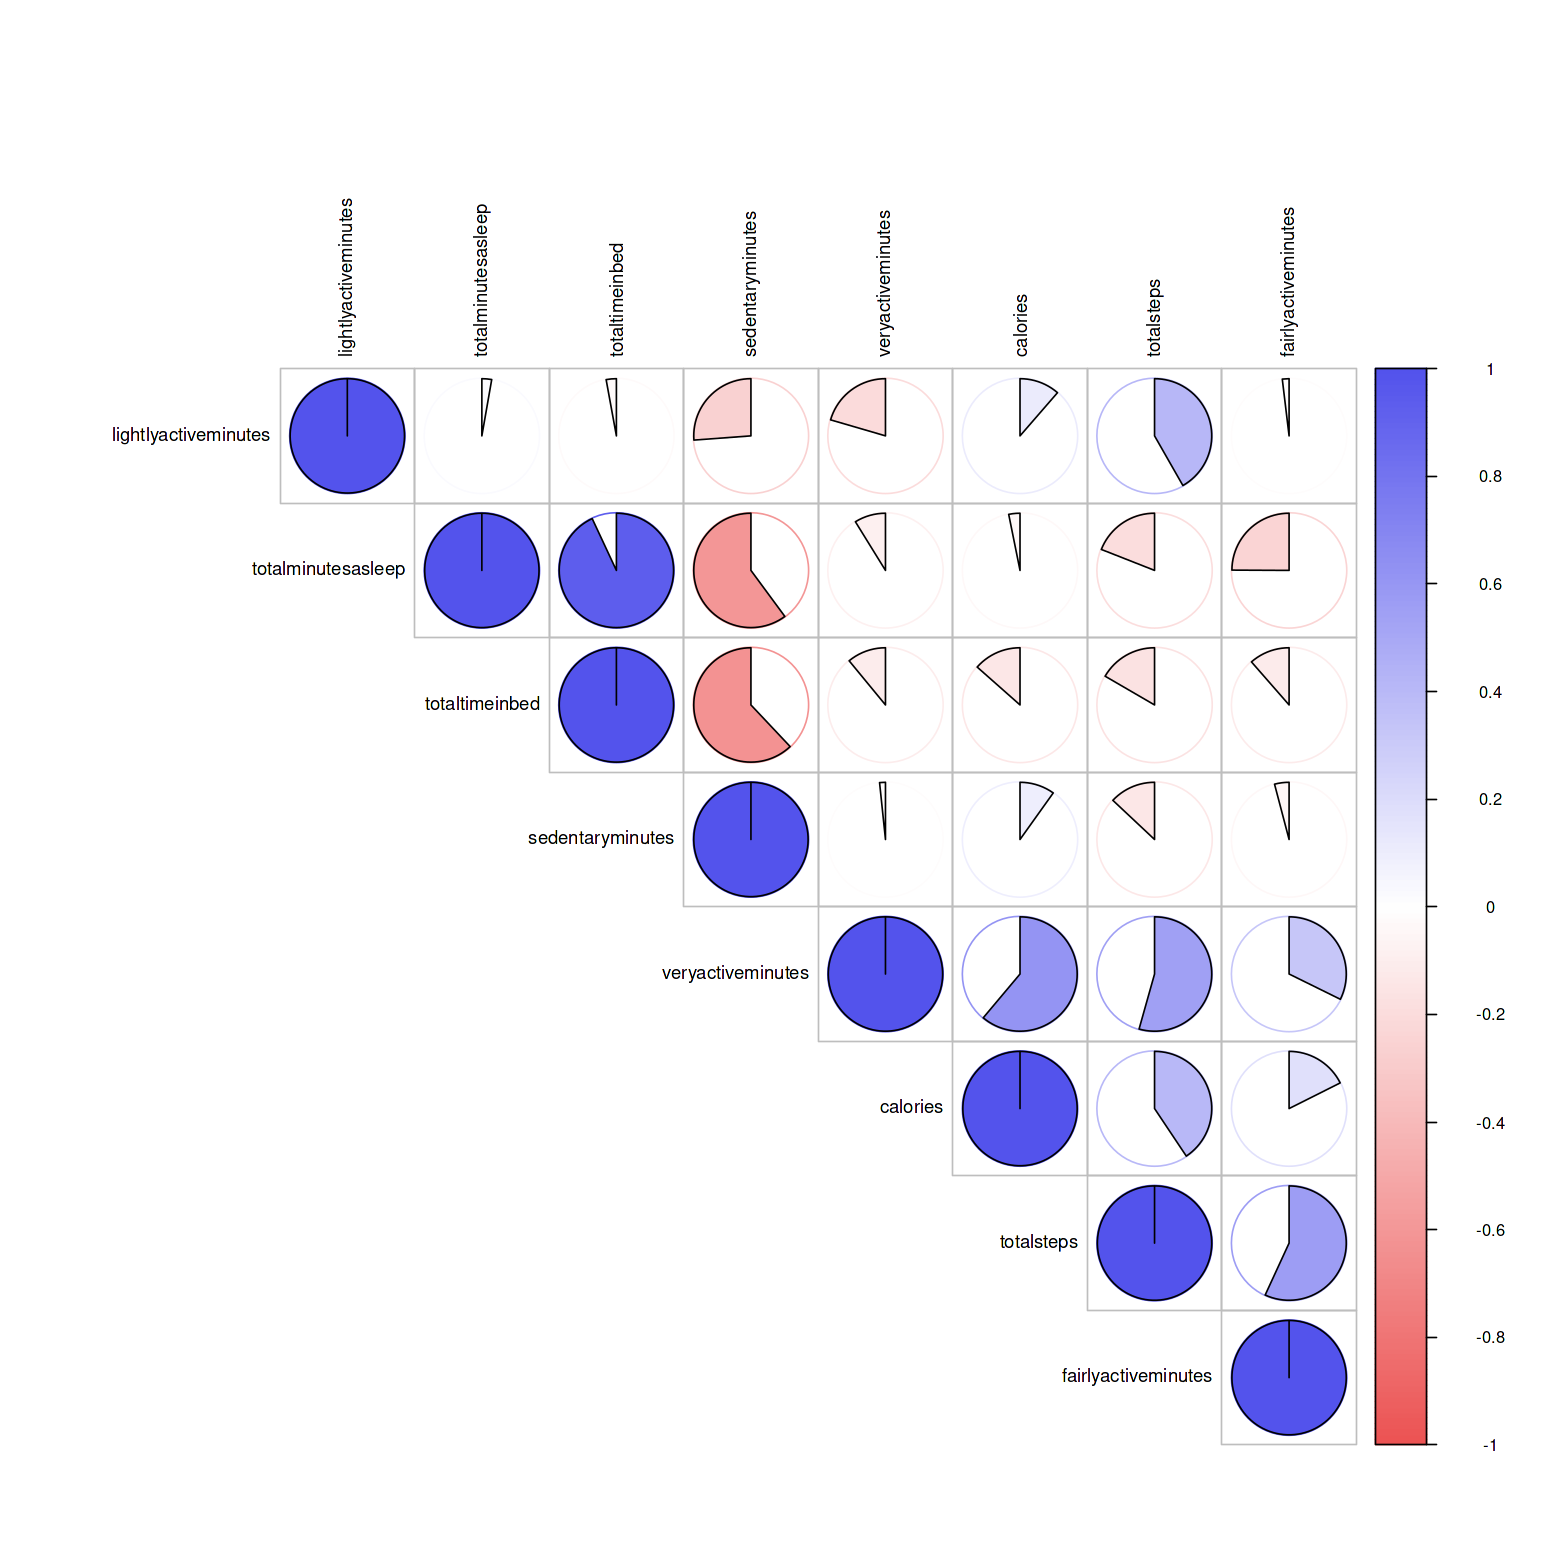

In [21]:
daily_corr <- combined_daily %>%
  select(totalsteps, lightlyactiveminutes, fairlyactiveminutes,
         veryactiveminutes, sedentaryminutes, calories,
         totalminutesasleep, totaltimeinbed)

cor(daily_corr)

options(repr.plot.width = 13, repr.plot.height = 13)

daily_matrix <- cor(daily_corr)
corrplot(daily_matrix, method = "pie", order = "hclust", type = "upper", 
         col = colorRampPalette(c("#ec5353", "#ffffff", "#5353ec"))(200),
         tl.cex = 0.9, cl.ratio = 0.20, tl.col = "black")

#### Principais correlações observadas
Forte correlação positiva entre **VeryActiveMinutes × Calories**, indicando que os usuários com mais tempo de atividade física intensa tendem a queimar mais calorias.


Correlação negativa moderada entre **SedentaryMinutes × TotalMinutesAsleep**, sugerindo que maior tempo sedentário pode estar associado a menor tempo de sono.

#### Combinar e agrupar os conjuntos hourly_calories, hourly_steps e hourly_intensities¶
Combinando os conjuntos hourly_calories, hourly_step e hourly_intensities pelas variáveis id, date, time, activityhour e weekday.

Utilizar a função inner_join() para manter somente os registros correspondentes em ambos os conjuntos de dados.


In [22]:
n_distinct(hourly_steps$id)
n_distinct(hourly_calories$id)
n_distinct(hourly_intensities$id)

[1] 33

[1] 33

[1] 33

Todos os três conjuntos possuem 33 registros de usuários distintos.

In [23]:
combined_hourly <- hourly_calories %>%
  inner_join(hourly_steps, by = c("id", "date", "time", "activityhour", "weekday")) %>%
  inner_join(hourly_intensities, by = c("id", "date", "time", "activityhour", "weekday"))

n_distinct((combined_hourly$id))
head(combined_hourly)

[1] 33

,id,activityhour,calories,time,date,weekday,steptotal,totalintensity,averageintensity
,<dbl>,<dttm>,<int>,<chr>,<date>,<ord>,<int>,<int>,<dbl>
1,1503960366,2016-04-12 00:00:00,81,00h,2016-04-12,terça,373,20,0.333333
2,1503960366,2016-04-12 01:00:00,61,01h,2016-04-12,terça,160,8,0.133333
3,1503960366,2016-04-12 02:00:00,59,02h,2016-04-12,terça,151,7,0.116667
4,1503960366,2016-04-12 03:00:00,47,03h,2016-04-12,terça,0,0,0.000000
5,1503960366,2016-04-12 04:00:00,48,04h,2016-04-12,terça,0,0,0.000000
6,1503960366,2016-04-12 05:00:00,48,05h,2016-04-12,terça,0,0,0.000000


Após a junção dos conjuntos, o número de usuários ainda é 33.

Agrupando por time para visualizar o comportamento médio dos usuários por hora.



In [24]:
timegrouped_hourly <- combined_hourly %>%
  group_by(time) %>%
  summarize(meanintensity = mean(totalintensity),
            meanssteps = mean(steptotal, na.rm = TRUE),
            meancalories = mean(calories, na.rm = TRUE))

head(timegrouped_hourly)

time,meanintensity,meanssteps,meancalories
<chr>,<dbl>,<dbl>,<dbl>
00h,2.1295503,42.188437,71.80514
01h,1.4190782,23.102894,70.16506
02h,1.0439443,17.110397,69.18650
03h,0.4437299,6.426581,67.53805
04h,0.6330472,12.699571,68.26180
05h,4.9506438,43.869099,81.70815


## 5. Visualizar - Compartilhando os Dados

#### Distribuição por dia da semana

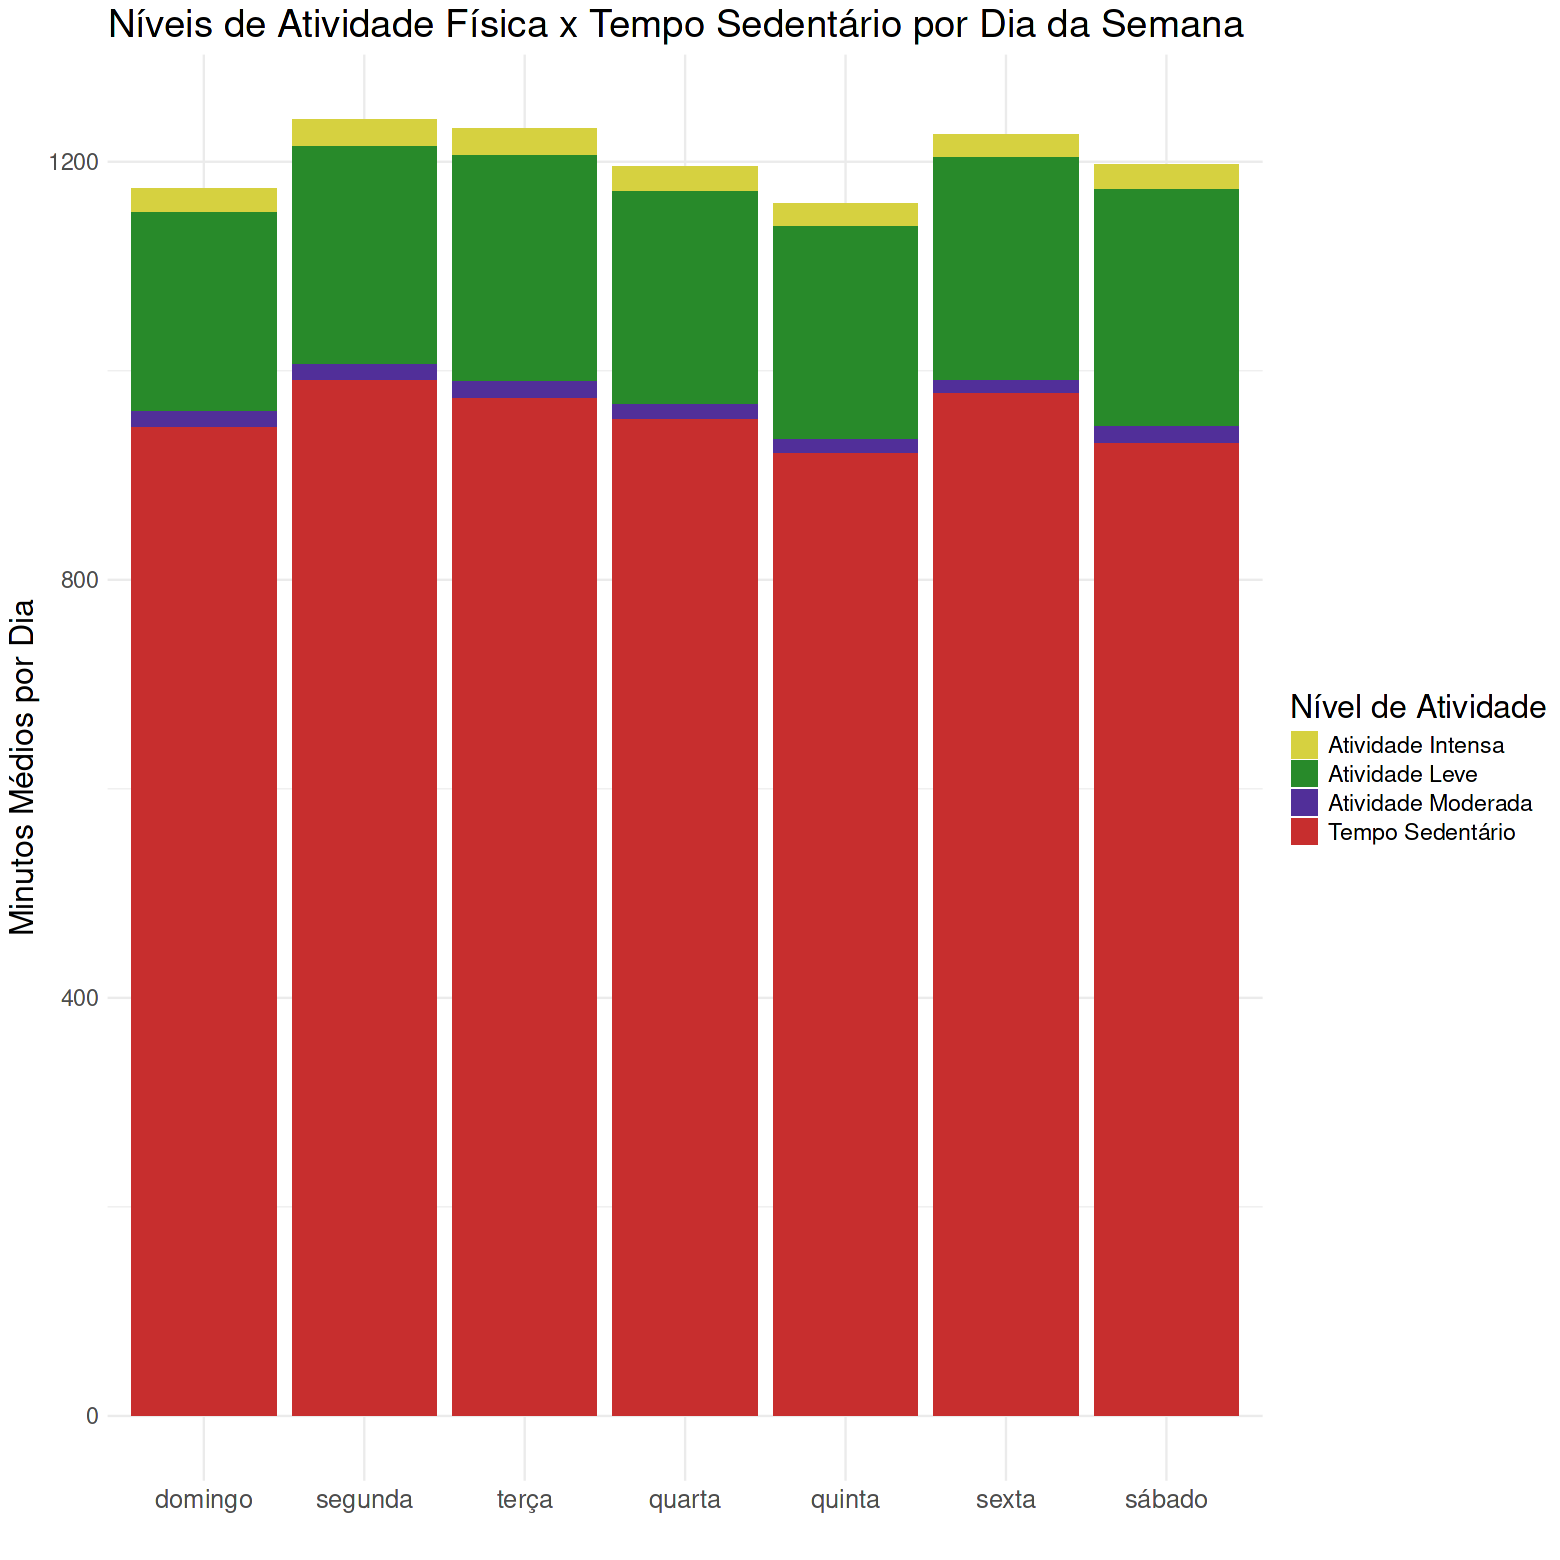

In [25]:
options(repr.plot.width = 13, repr.plot.height = 13)

ggplot(weekday_activity, aes(x = weekday, y = mean_minutes, fill = activity_level)) +
  geom_col() +
  scale_fill_manual(values = c("Atividade Leve" = "#288a2a",
                               "Atividade Moderada" = "#512f99",   
                               "Atividade Intensa"   = "#d6d140",
                               "Tempo Sedentário" = "#c72e2e")) +
  theme_minimal() +
  theme(axis.text.x = element_text(hjust = 0.5, size = 15),
       title = element_text(size = 19),
       text = element_text(size = 17)) +
  labs(title = "Níveis de Atividade Física x Tempo Sedentário por Dia da Semana",
       x = "", y = "Minutos Médios por Dia",
       fill = "Nível de Atividade")

Ao Analisar e possível perceber que:
* O comportamento **sedentário** é predominante, mesmo em finais de semana.
* Preferencial por atividades leves.
* Atividades moderadas e pesadas poucas durante a semana.

#### Distribuição de tempo por nível de atividade

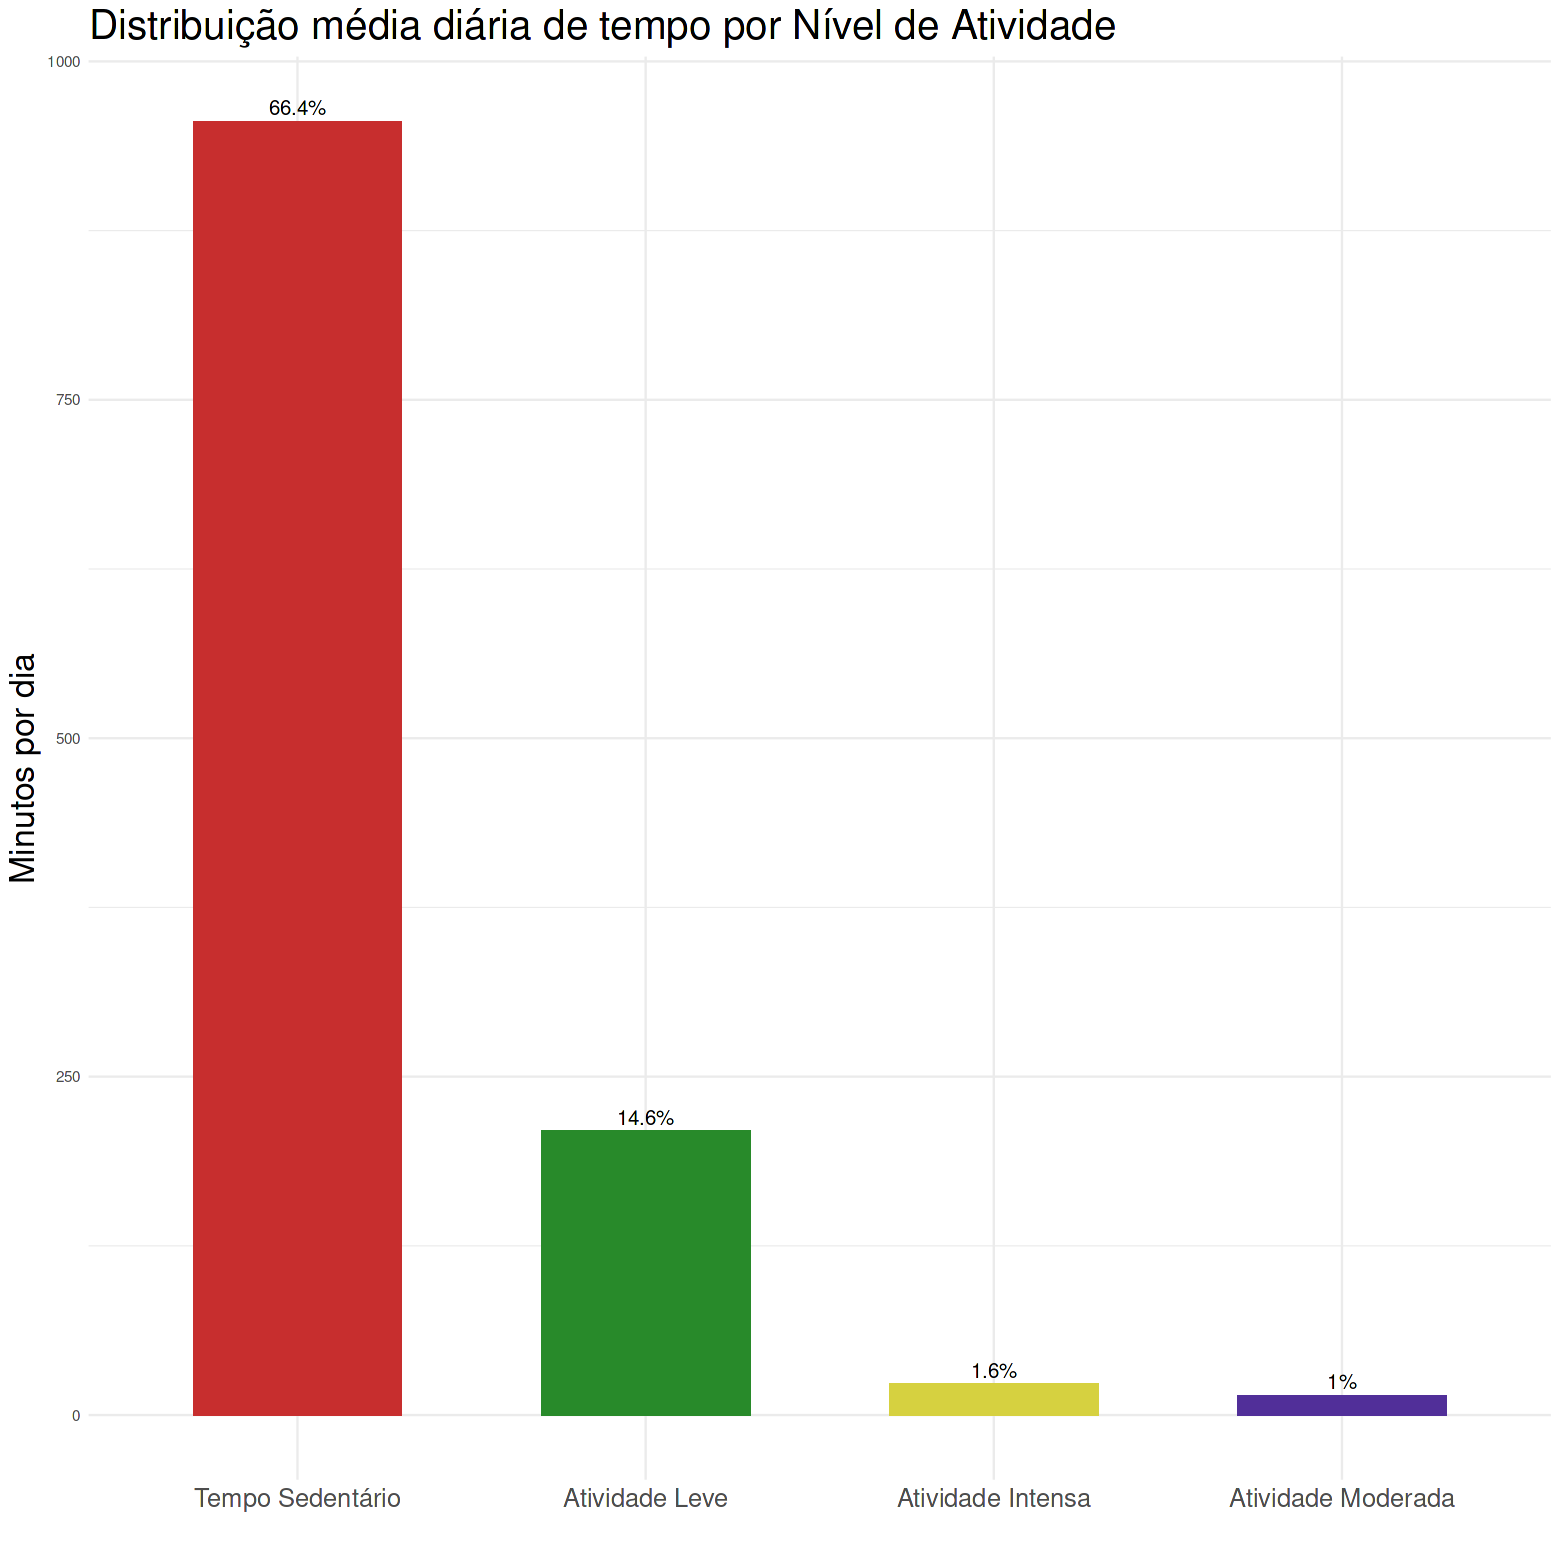

In [26]:
options(repr.plot.width = 13, repr.plot.height = 13)

ggplot(activity_means, aes(x = reorder(activity, -minutes), y = minutes, fill = activity)) +
  geom_bar(stat = "identity", width = 0.6) +
  geom_text(aes(label = Label), vjust = -0.4, size = 4.2) +
  scale_fill_manual(
    values = c("Atividade Leve" = "#288a2a",
               "Atividade Moderada" = "#512f99",
               "Atividade Intensa" = "#d6d140",
               "Tempo Sedentário" = "#c72e2e")) +
theme_minimal() +
theme(axis.text.x = element_text(size = 15),
      title = element_text(size = 20),
      legend.position = "none")+
  labs(title = "Distribuição média diária de tempo por Nível de Atividade",
    x = "", y = "Minutos por dia")

#### Correlação entre tempo sedentário e tempo de sono.

`geom_smooth()` using formula = 'y ~ x'


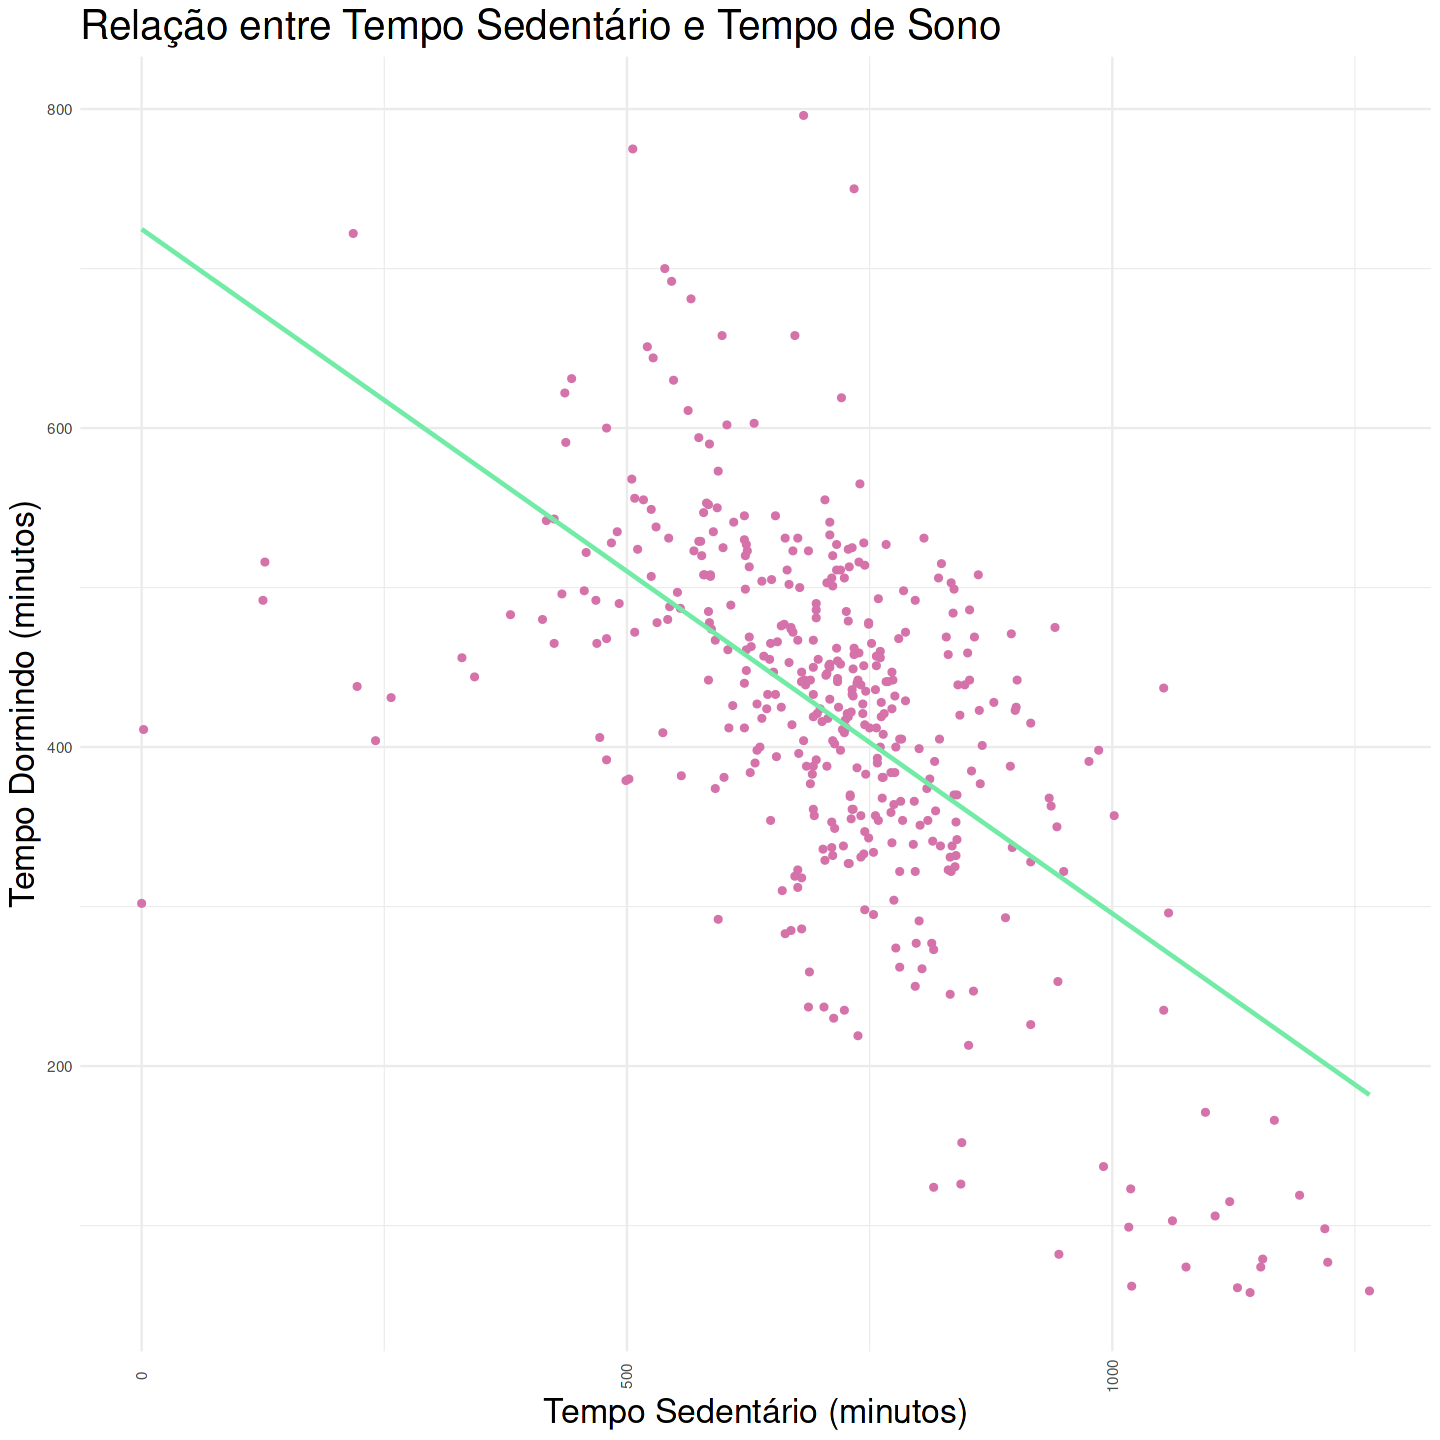

In [27]:
options(repr.plot.width = 12, repr.plot.height = 12)
ggplot(data = combined_daily, aes(x = sedentaryminutes, y = totalminutesasleep)) +
  geom_point(color = "#d472a9") +
  geom_smooth(method = "lm", se = FALSE, color = "#71eba5") +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 90,vjust = 0.5),
        title = element_text(size = 20)) +
  labs(title = "Relação entre Tempo Sedentário e Tempo de Sono",
       x = "Tempo Sedentário (minutos)",
       y = "Tempo Dormindo (minutos)")

Existe uma correlação negativa moderada entre Tempo sedentário e minutos dormindo, como mostrado no correlograma, sugerindo que maior tempo sedentário pode esta, associado menor tempo de sono.

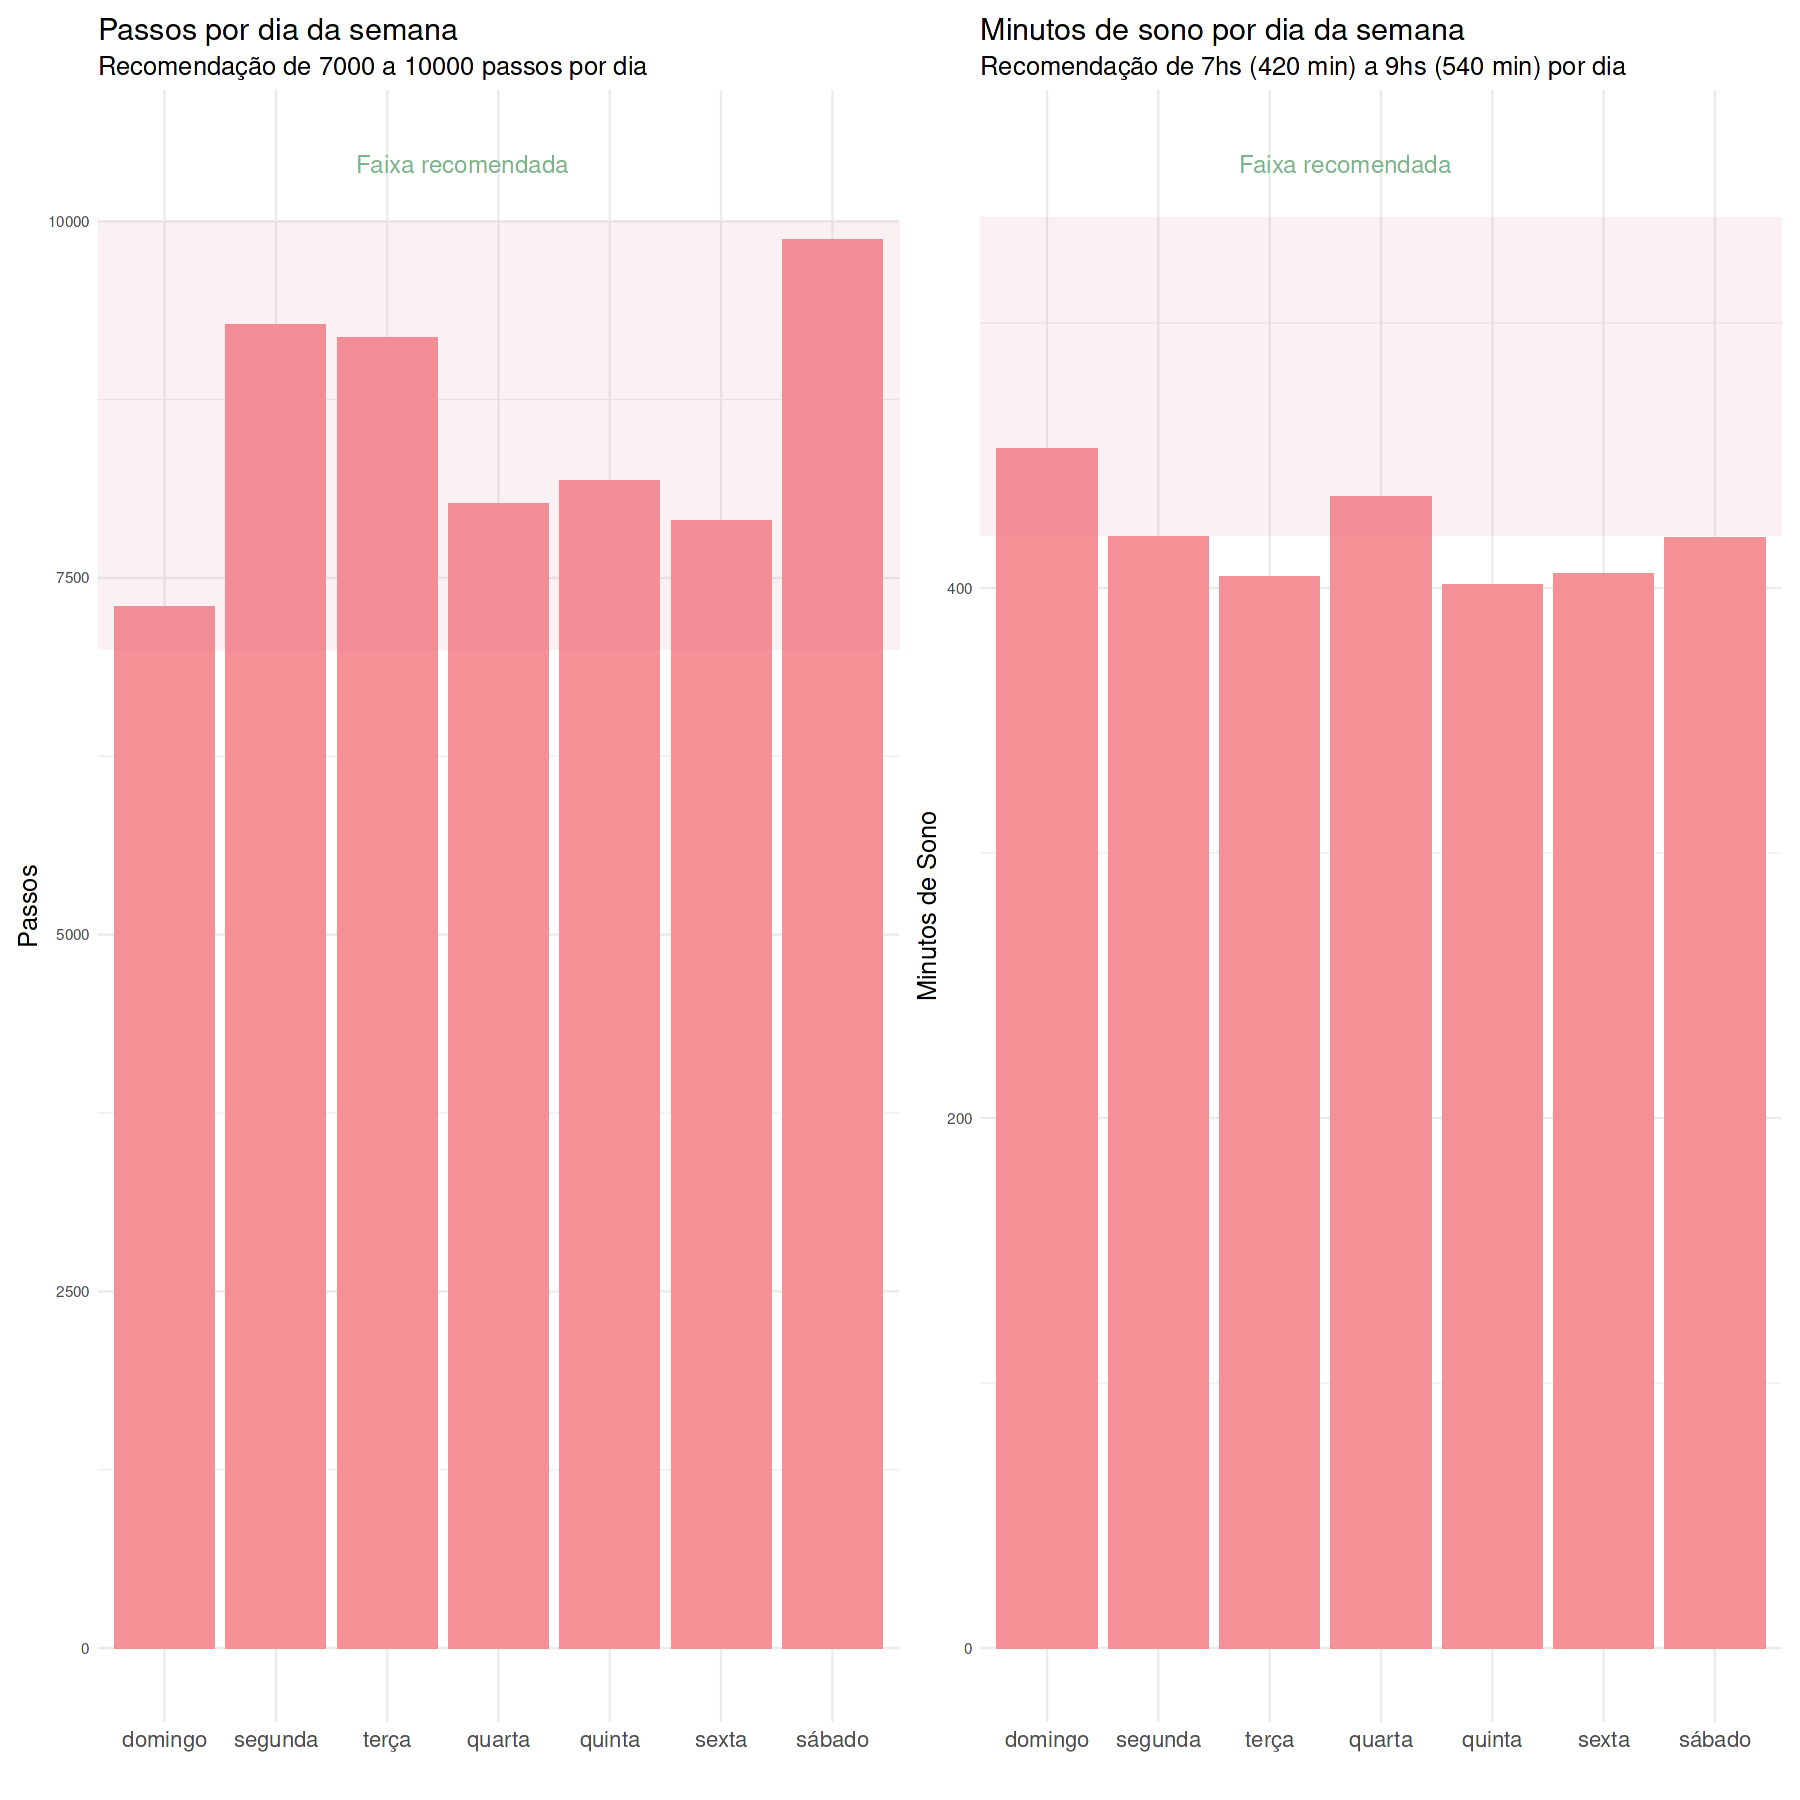

In [28]:
grafico1 <- ggplot(data = weekdaygrouped_daily, aes(x = weekday, y = meansteps)) +
  geom_col(fill = "#f59097") +
  annotate("rect", xmin = -Inf, xmax = Inf, ymin = 7000, ymax = 10000,
           alpha = 0.1, fill = "#d97781")+
  theme_minimal() +
  theme(axis.text.x = element_text(size = 13),
        title = element_text(size = 15)) +
  annotate("text", x = 1.2, y = 10400,
           label = "Faixa recomendada", color = "#7db389", size = 5, hjust = -0.8) +
  labs(title = "Passos por dia da semana",
       subtitle = "Recomendação de 7000 a 10000 passos por dia" ,
       x= "", y = "Passos")

grafico2 <- ggplot(data = weekdaygrouped_daily, aes(x = weekday, y = meanasleep)) +
  geom_col(fill = "#f59097") +
  annotate("rect", xmin = -Inf, xmax = Inf, ymin = 420, ymax = 540,
           alpha = 0.1, fill = "#d97781") +
  theme_minimal() +
  theme(axis.text.x = element_text(size = 13),
        title = element_text(size = 15)) +
  annotate("text", x = 1.2, y = 560,
           label = "Faixa recomendada", color = "#7db389", size = 5, hjust = -0.8) +
  labs(title = "Minutos de sono por dia da semana",
       subtitle = "Recomendação de 7hs (420 min) a 9hs (540 min) por dia",
       x= "", y = "Minutos de Sono")

options(repr.plot.width = 15, repr.plot.height = 15)
grafico1 + grafico2

O primeiro gráfico é o gráfico de passos que indica que a média diária se encontra na faixa recomendada de 7.000 a 10.000 passos, ideal para uma vida saudável.

O segundo gráfico, o gráfico de sono, revela que os usuários não atingem a recomendação de 7 a 9 horas de sono por noite, o que pode impactar negativamente o bem-estar geral.

#### Hora do dia onde os usuários são mais ativos, dão mais passos e queimam mais calorias

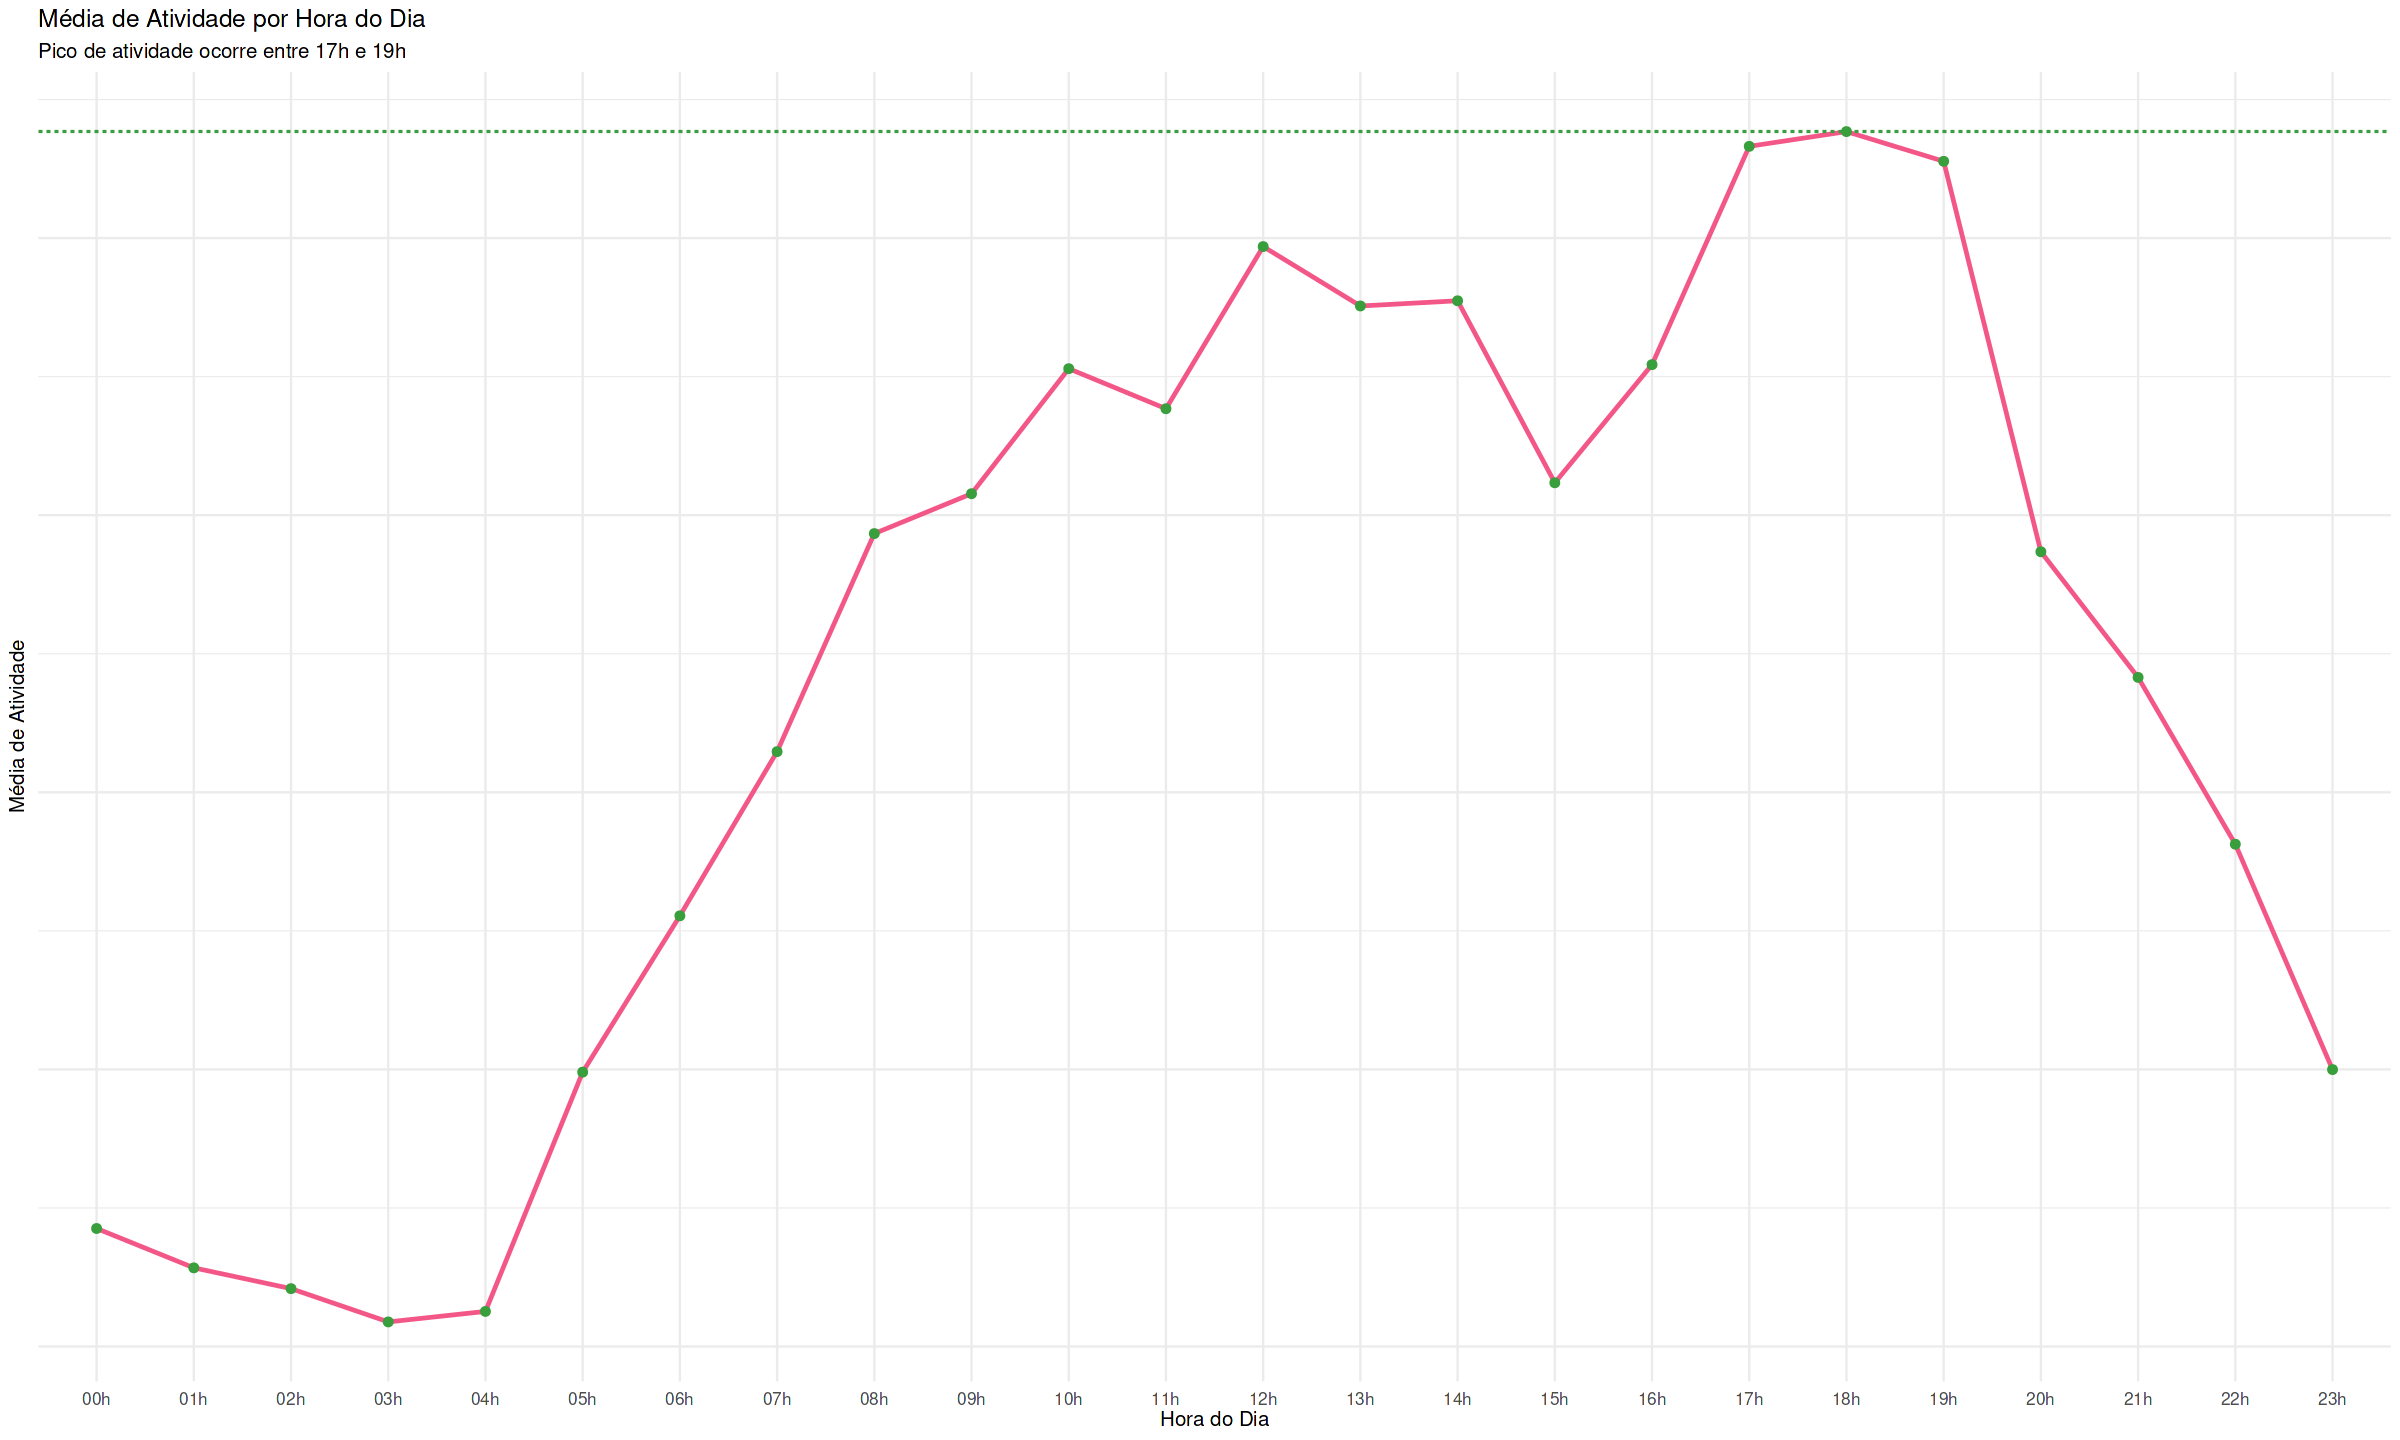

In [29]:
# Atividade
grafico1 <- ggplot(data = timegrouped_hourly, aes(x = time, y = meanintensity, group = 1)) +
  geom_line(color = "#f25788", linewidth = 1) +
  geom_point(color = "#399e3c", size = 2) +
  geom_hline(yintercept = max(timegrouped_hourly$meanintensity),
             linetype = "dashed", color = "#399e3c", linewidth = 0.7) +
  theme_minimal() +
  theme(axis.text.x = element_text(vjust = 0.4, size = 10),
        title = element_text(size = 12),
        axis.text.y = element_blank(),
        axis.ticks.y = element_blank()) +
  labs(title = "Média de Atividade por Hora do Dia",
       subtitle = "Pico de atividade ocorre entre 17h e 19h",
       x = "Hora do Dia", y = "Média de Atividade")

options(repr.plot.width = 20, repr.plot.height = 12)
grafico1

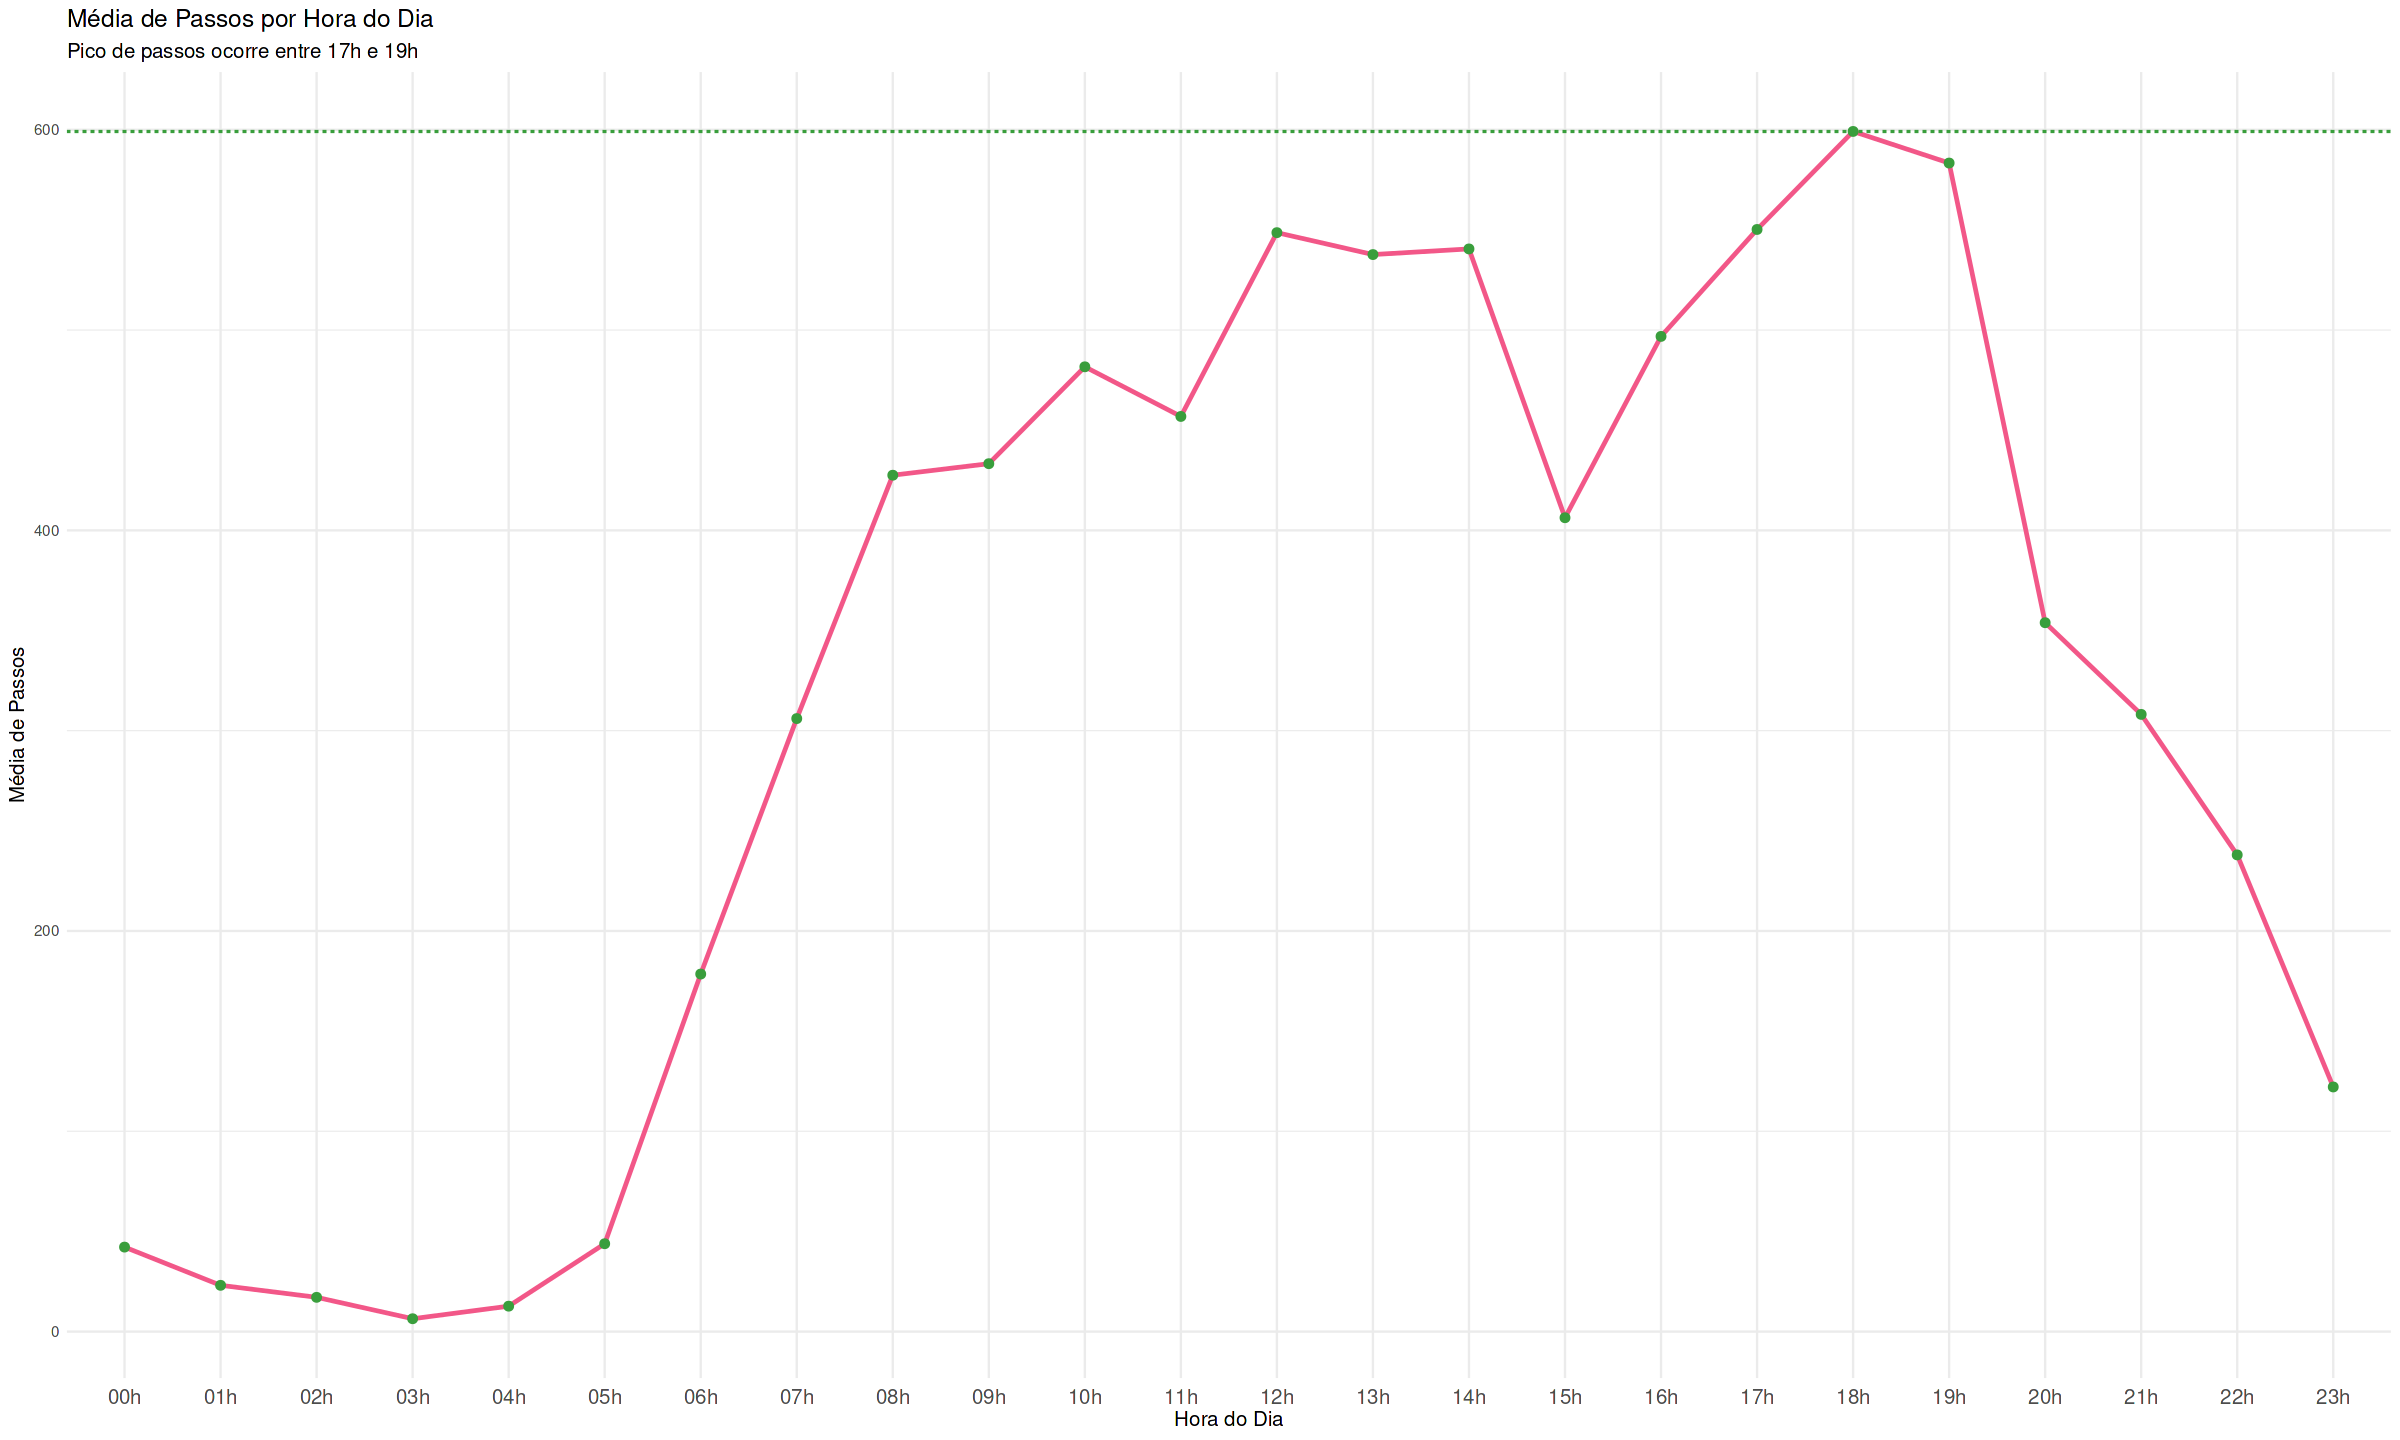

In [30]:
#Passos
grafico2 <- ggplot(data = timegrouped_hourly, aes(x = time, y = meanssteps, group = 1)) +
  geom_line(color = "#f25788", linewidth = 1) +
  geom_point(color = "#399e3c", size = 2) +
  geom_hline(yintercept = max(timegrouped_hourly$meanssteps),
             linetype = "dashed", color = "#399e3c", linewidth = 0.7) +
  theme_minimal() +
  theme(axis.text.x = element_text(vjust = 0.5, size = 12),
        title = element_text(size = 12)) +
  labs(title = "Média de Passos por Hora do Dia",
       subtitle = "Pico de passos ocorre entre 17h e 19h",
       x = "Hora do Dia", y = "Média de Passos")

options(repr.plot.width = 20, repr.plot.height = 12)
grafico2

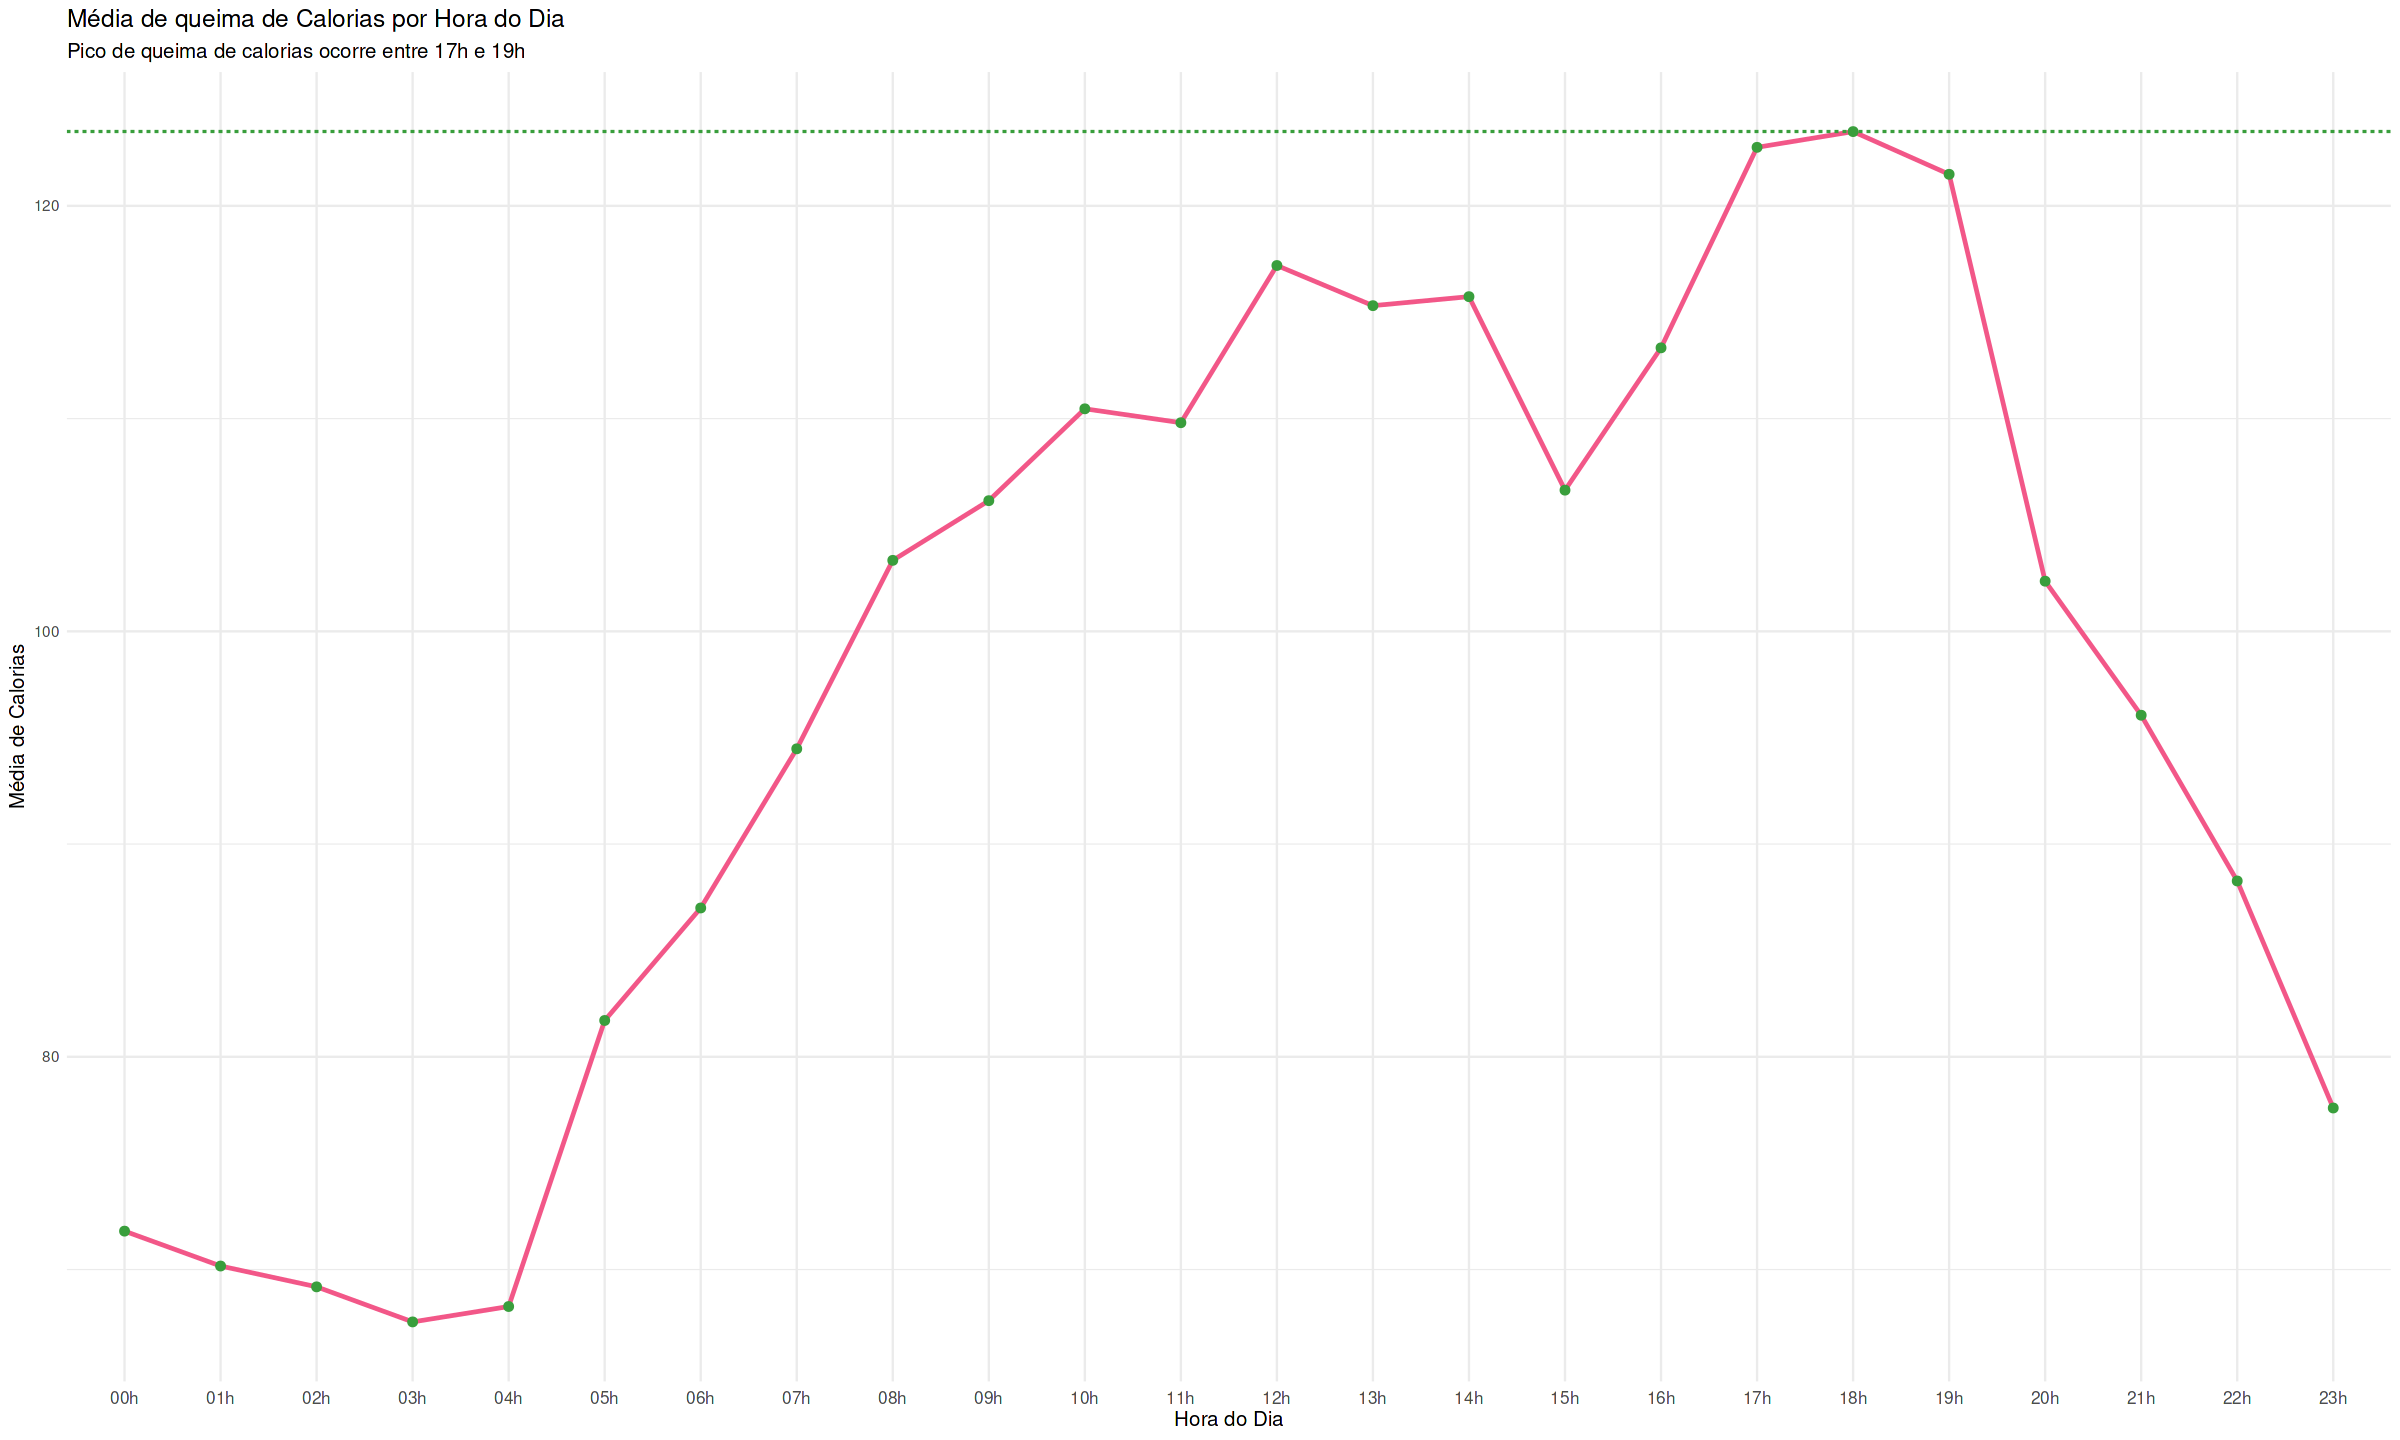

In [31]:
# Calorias
grafico3 <- ggplot(data = timegrouped_hourly, aes(x = time, y = meancalories, group = 1)) +
  geom_line(color = "#f25788", linewidth = 1) +
  geom_point(color = "#399e3c", size = 2) +
  geom_hline(yintercept = max(timegrouped_hourly$meancalories),
             linetype = "dashed", color = "#399e3c", linewidth = 0.7) +
  theme_minimal() +
  theme(axis.text.x = element_text(vjust = 0.5, size = 10),
        title = element_text(size = 12)) +
  labs(title = "Média de queima de Calorias por Hora do Dia",
       subtitle = "Pico de queima de calorias ocorre entre 17h e 19h",
       x = "Hora do Dia", y = "Média de Calorias")

options(repr.plot.width = 20, repr.plot.height = 12)
grafico3

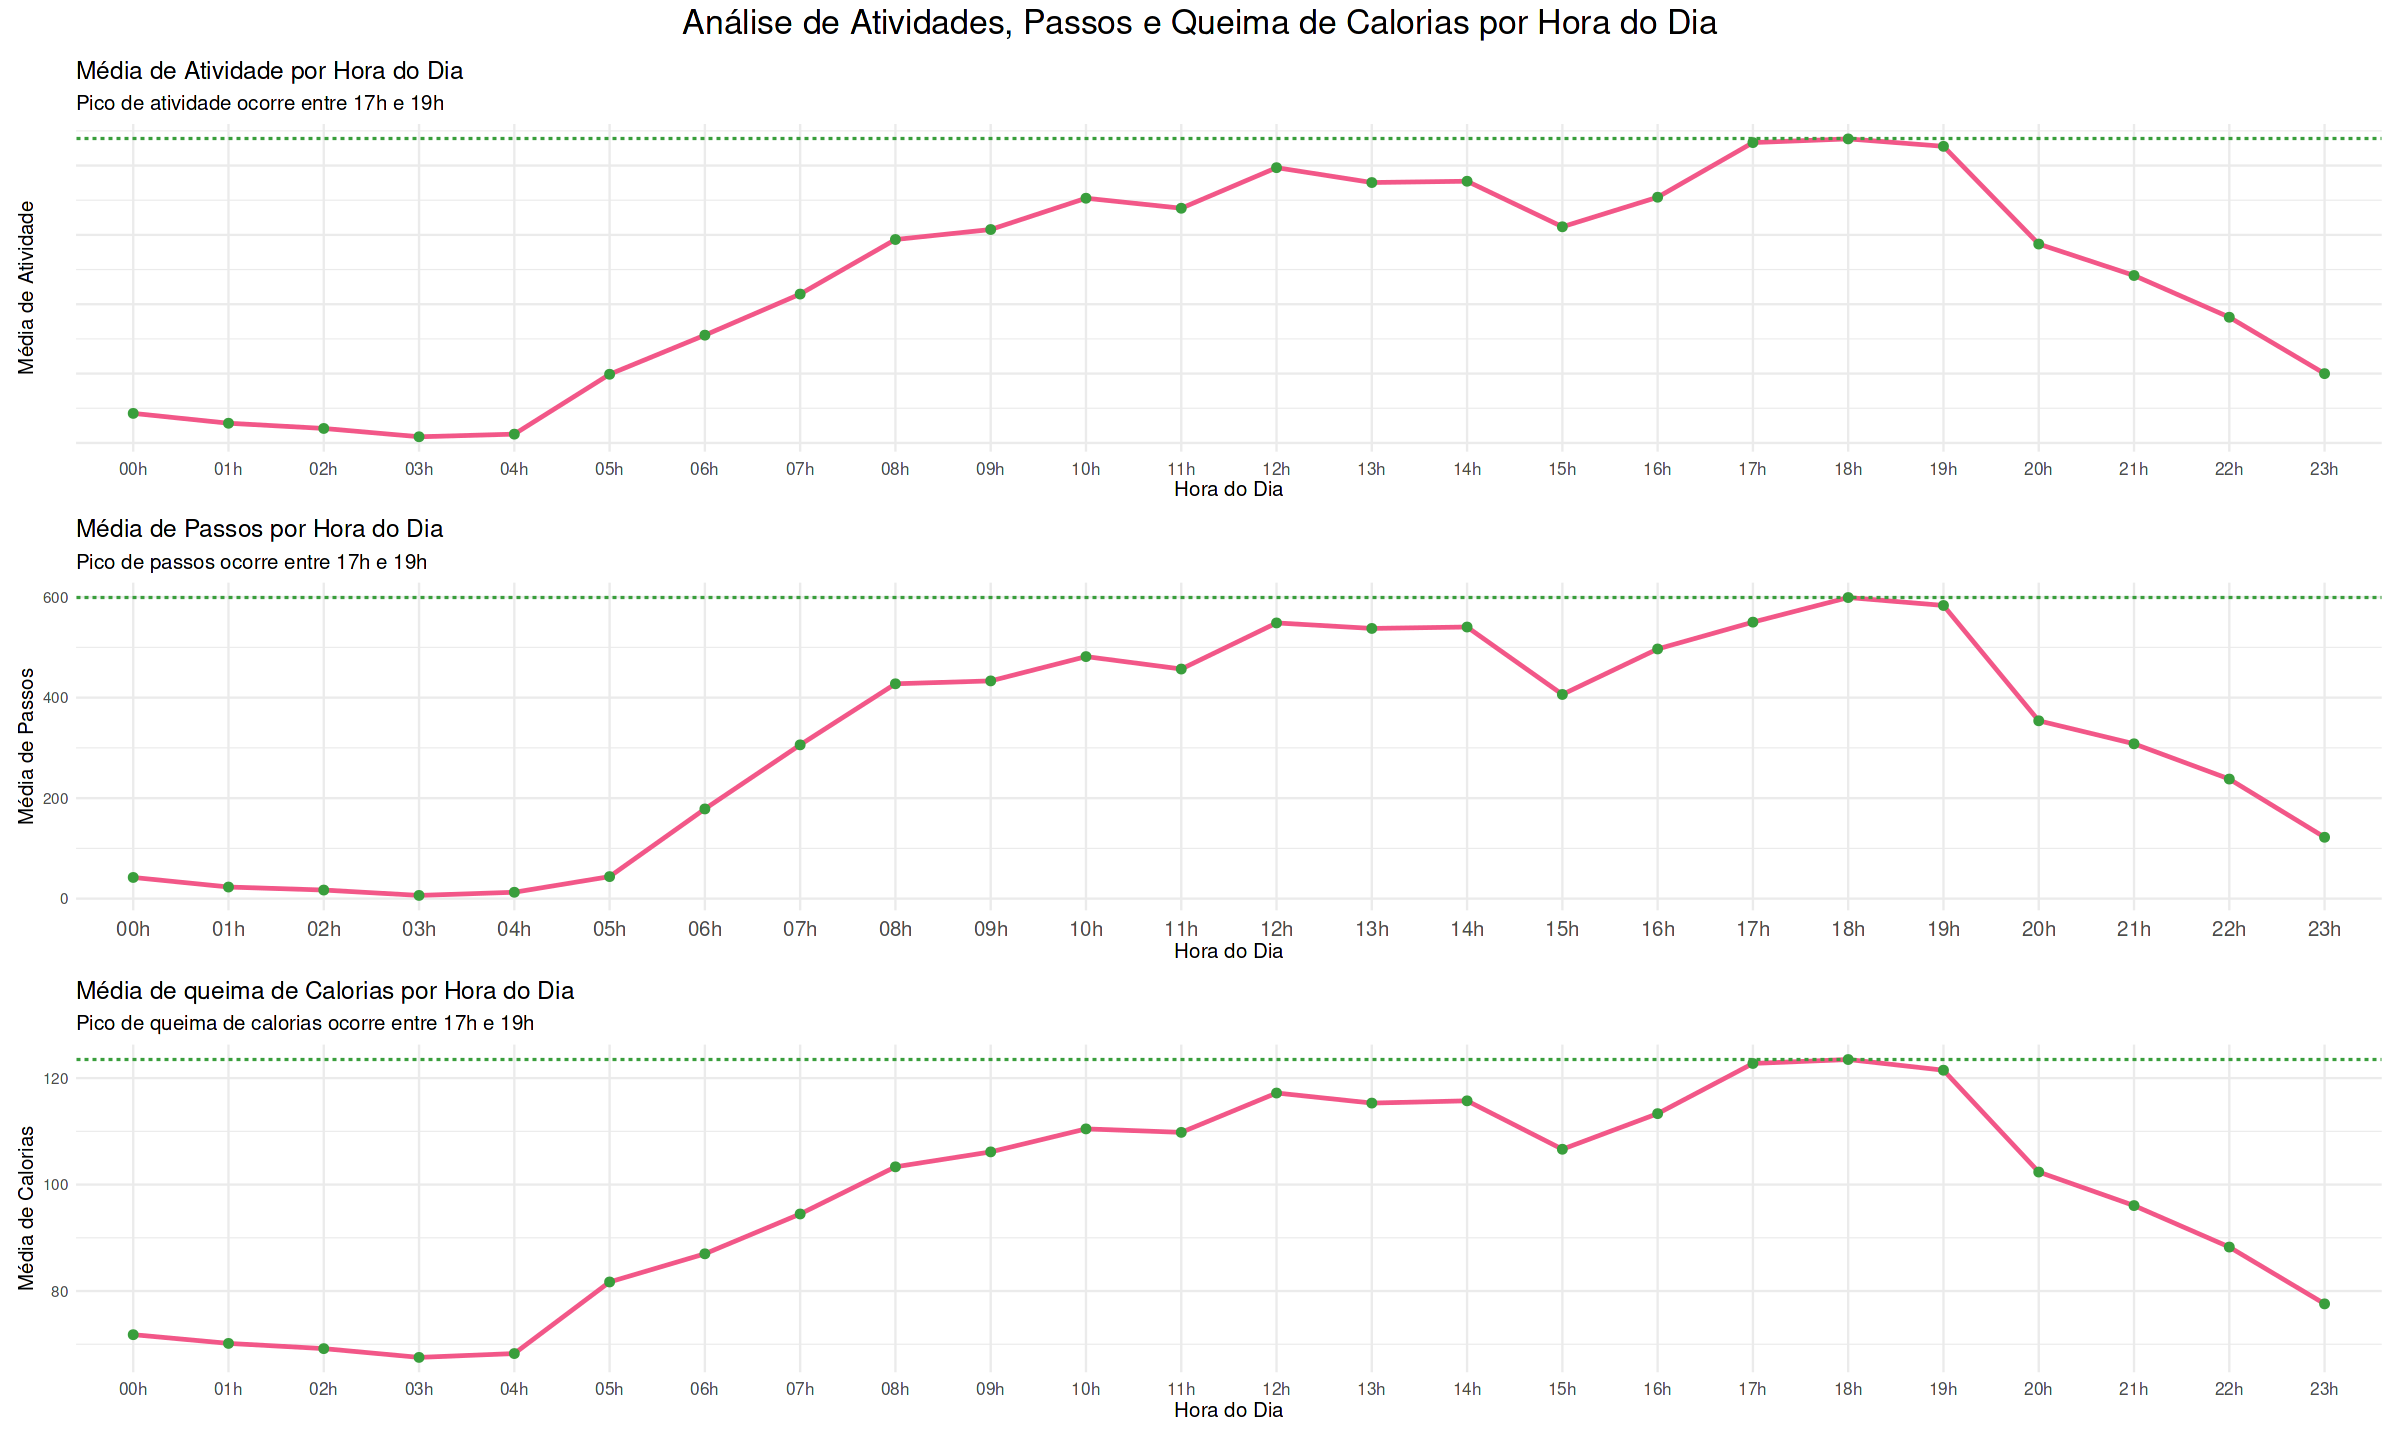

In [32]:
# Agrupar verticalmente
options(repr.plot.width = 20, repr.plot.height = 12)
(grafico1 / grafico2 / grafico3) + 
  plot_annotation(
    title = "Análise de Atividades, Passos e Queima de Calorias por Hora do Dia",
    theme = theme(plot.title = element_text(size = 20, hjust = 0.5)))


Ao analisar os gráficos, atividades físicas, passos e queima de calorias é possível notar um padrão consistente entre os usuários. Existe um aumento grande e gradual a partir das 06h da manhã, mais com um pico elevado e concentrado das 17h até as 19h. Esse intervalo coincide com usuários **voltando para casa depois do trabalho** ou **iniciando atividades físicas** como academia, caminhadas ou corridas.

Após as 20h o declínio gradual e notado em todas as métricas, sugerindo um comportamento sedentário mais a noite, onde provavelmente os usuários estão encerrando as atividades físicas e descansando.

## 6. Agir - Conclusão dos dados

### Objetivo 
* Identificar tendências no uso de dispositivos inteligentes.
   * Como essas tendências podem ser aplicadas nos clientes da bellabeat.
   * Como essas tendências podem ajudar na estratégia de marketing da bellabeat.


#### **1 - Atividades físicas**
A Maioria das atividades físicas acontecem em 17h a 19h. A média de passos observada esta na faixa recomendada para trazer benefícios a saúde, dessa forma essa media precisar sem mantida e incentivada.

**Estrategia para atividades físicas**
* Monitorar intervalos de maior Atividade: Ao invés de tentar mudar radicalmente os hábitos dos usuários, essa tática aproveita os momentos em que eles já estão mais propensos a se exercitar.   
* Saúde integral: alongamento e hidratação são cruciais para a recuperação, prevenção de lesões e bem-estar geral, mas frequentemente negligenciados. Incluí-los mostra um cuidado mais holístico com a saúde do usuário.
* Educação e Conscientização: Muitos usuários podem não estar cientes das recomendações de atividade física. Informá-los sobre os 75 minutos de atividade intensa ou 150 minutos de atividade moderada por semana pode dar a eles uma meta clara.

#### **2 - Sono**
A Maioria dos usuários fica abaixo do da faixa de sono recomendada que é de 7h a 9h de sono, assim tendo noites de sono inconsistentes.

**Estrategia para o Sono**
* Personalização e autonomia: dar ao usuário o controle para definir seu próprio horário de dormir aumenta a adesão.
* Rotina de Sono: Alerta preparatórios ajudam a construir uma rotina de sono consistente, crucial para regular o ciclo circadiano.
* Redução de Estímulos: Dicas para diminuir o tempo de tela assim combatendo um dos maiores vilões do sono moderno.
* Identificação de Padrões: Permite que o usuário identifique fatores que afetam o sono (exemplo: "dormi mal após comer tarde", "dormi bem após fazer exercícios").
* Engajamento: Transforma o sono em uma métrica rastreável, incentivando os usuários a melhorar seus hábitos ao ver seu progresso.

#### **3 - Sedentarismo**
A maioria dos usuários permanece, em média, 16 horas por dia em estado sedentário. Esse valor precisa ser diminuído para promover uma vida mais saudável.

**Estrategia para o Sedentarismo**
* Conscientização e Motivação: Muitas pessoas subestimam os perigos do sedentarismo prolongado. Educar sobre os riscos (doenças crônicas, piora do sono, etc.) e os benefícios da redução (mais energia, melhor humor, sono de qualidade) pode ser um poderoso catalisador para a mudança de comportamento.
* Conexão com Outros Hábitos: Ao ligar a redução do sedentarismo à melhoria do sono e da saúde geral, você cria uma narrativa mais completa e motivadora para o usuário.
* Quebra de Padrão: Interromper o sedentarismo com pequenas pausas ativas é mais eficaz do que esperar por um período de exercício mais longo. Mesmo 5 minutos de caminhada a cada hora podem fazer uma grande diferença.
* Simplicidade: Os lembretes são para ações simples e de baixa barreira (levantar, caminhar um pouco, alongar), tornando-os fáceis de serem incorporados.



##  Fim
Essa é a minha primeira analises de muitas.
Espero que esta análise tenha sido útil e que os insights apresentados inspirem novas ideias para promover um estilo de vida mais saudável. Agradeço a todos que dedicaram seu tempo para explorar este estudo de caso.